# Universidad de Buenos Aires
# Aprendizaje Profundo - TP3
# Cohorte 26 - 4to bimestre 2026


## **Alumno 1:** Rodrigo Hernández

Este tercer y último TP se debe entregar hasta las **23:59hs del miércoles 21 de octubre (hora de Argentina)**.

La resolución del TP puede realizarse de forma **individual, en parejas o hasta en grupos de 3 como máximo**. Sin embargo, no se recomienda repartir las preguntas entre los integrantes, sino que todos los integrantes deben trabajar conjuntamente en la resolución de cada pregunta. De esta manera, se promueve el debate, la discusión y la construcción de una conclusión compartida sobre cómo abordar y resolver cada pregunta.

Pueden utilizar los contenidos vistos en clase y otra bibliografía que consideren que les haga falta. Si se toman ideas de fuentes externas deben ser correctamente citadas incluyendo el correspondiente link o página de libro.

ESTE TP3 EQUIVALE A UN TERCIO DE SU NOTA FINAL.

El formato de entrega debe ser un link a un notebook de google colab. Permitir acceso a gvilcamiza.ext@fi.uba.ar y **habilitar los comentarios, para poder darles el feedback**. Si no lo hacen así no se podrá dar el feedback respectivo por cada pregunta.

**El desarrollo del TP se debe hacer obligatoriamente en un notebook**, ya sea en un Google Colab o en un Jupyter Notebook para quienes quieran desarrollarlo en su propia PC local. Pero no se aceptarán archivos `.py` o links a repos de github con múltiples archivos. El entregable debe ser un link a un único archivo en formato `.ipynb`.

El envío **se realizará en el siguiente link de google forms: [link](https://forms.gle/v2e6LA4umZ6VM8sQ8)**. Tanto los resultados, gráficas, como el código y las explicaciones deben quedar guardados y visualizables en el colab.

**NO SE VALIDARÁN ENVÍOS POR CORREO, EL MÉTODO DE ENTREGA ES SOLO POR EL FORMS.**

**Consideraciones a tener en cuenta:**
- Se entregará 1 solo colab para este TP3.
- Renombrar el archivo de la siguiente manera: **PRIMERAPELLIDOALUMNO1-PRIMERAPELLIDOALUMNO2-PRIMERAPELLIDOALUMNO3-TP3-Co26.ipynb**
O en caso hacerlo individual usar: **PRIMERAPELLIDO-PRIMERNOMBRE-TP3-Co26.ipynb**
- Los códigos deben poder ejecutarse.
- **IMPORTANTE:** Los resultados, cómo el código, los gráficos, los prints y las explicaciones deben quedar guardados y visualizables en el mismo notebook.
- No ocultar celdas, todas se deben poder ver desde el inicio.
- **Prestar mucha atención a cada consigna, responder las preguntas justo debajo del enunciado que corresponda.**
- Solo se revisarán los trabajos que hayan sido enviados por el forms.

# **CLASIFICADOR DE EMOCIONES**

El objetivo de este trabajo es construir una red neuronal convolucional (CNN) utilizando Pytorch, capaz de clasificar emociones humanas a partir de imágenes faciales. El clasificador deberá identificar una de las 7 emociones básicas: alegría, tristeza, enojo, miedo, sorpresa, disgusto y seriedad. El dataset se encuentra en este link: https://drive.google.com/file/d/1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT/view?usp=sharing

Les recomiendo usar el siguiente código para poder obtener las imágenes fácilmente desde ese link. Pero son libres de descargar las imágenes como mejor les parezca.

In [1]:
import gdown
import zipfile
import os

url = "https://drive.google.com/uc?id=1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT"
output = "data/archivo.zip"            # rutas relativas: funcionan igual en Colab (/content) y en local

destino = "data/datos_zip"
os.makedirs(destino, exist_ok=True)

if not os.path.exists(output):
    gdown.download(url, output, quiet=False)

with zipfile.ZipFile(output, 'r') as zip_ref:
    zip_ref.extractall(destino)

DATASET_ROOT_TRAIN = 'data/datos_zip/dataset_emociones/train'
DATASET_ROOT_VAL   = 'data/datos_zip/dataset_emociones/validation'

## 1. Preprocesamiento de Datos (2 puntos)

Antes de entrenar el modelo, se debe analizar qué tipo de preprocesamiento se debe aplicar a las imágenes. Para esto, se puede considerar uno o más aspectos como:

- Tamaño
- Relación de aspecto
- Color o escala de grises
- Cambio de dimensionalidad
- Normalización
- Balanceo de datos
- Data augmentation
- etc.

Sean criteriosos y elijan solo las técnicas que consideren pertinentes para este caso de uso en específico.

Recomendación: usar `torchvision.transforms` para facilitar el preprocesamiento. Lean su documentación si tienen dudas: https://docs.pytorch.org/vision/0.14/transforms.html



#### Respuesta 1

Antes de decidir nada miro qué hay en las carpetas: cuántas imágenes hay de cada emoción, de qué tamaño son y en qué color vienen.

In [2]:
# ----------------------------------------------------------------------
# LIBRERÍAS, SEMILLA Y DISPOSITIVO
# ----------------------------------------------------------------------
import time
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

SEMILLA = 0
torch.manual_seed(SEMILLA)
torch.backends.cudnn.deterministic = True      # en GPU, para que re-ejecutar dé lo mismo o casi
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("dispositivo:", device)

dispositivo: mps


          train  validación  % train  % validación   peso
alegría    4772        1185     38.9          38.6  0.367
seriedad   2524         680     20.6          22.2  0.695
tristeza   1982         478     16.2          15.6  0.884
sorpresa   1290         329     10.5          10.7  1.359
disgusto    717         160      5.8           5.2  2.445
enojo       705         162      5.7           5.3  2.487
miedo       281          74      2.3           2.4  6.238

total: 12,271 imágenes en train y 3,068 en validación
alegría tiene 17.0 veces más imágenes de train que miedo


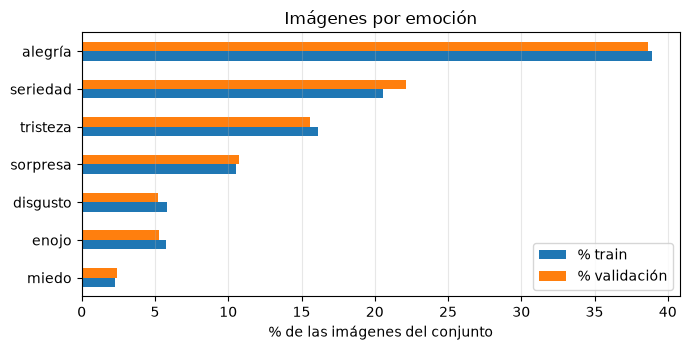

In [3]:
# ----------------------------------------------------------------------
# CUÁNTAS IMÁGENES HAY DE CADA EMOCIÓN
# ----------------------------------------------------------------------
train_ds = datasets.ImageFolder(DATASET_ROOT_TRAIN)      # sin transformación: por ahora solo las rutas y las etiquetas
val_ds   = datasets.ImageFolder(DATASET_ROOT_VAL)
assert train_ds.classes == val_ds.classes               # mismas carpetas y en el mismo orden

NOMBRE = {c: "alegría" if c == "alegria" else c for c in train_ds.classes}     # nombre de carpeta -> nombre para mostrar
CLASES = [NOMBRE[c] for c in train_ds.classes]

conteo = pd.DataFrame({"train": np.bincount(train_ds.targets), "validación": np.bincount(val_ds.targets)}, index=CLASES)
conteo["% train"] = 100 * conteo["train"] / conteo["train"].sum()
conteo["% validación"] = 100 * conteo["validación"] / conteo["validación"].sum()
# peso de cada clase para la función de costo: n_total / (n_clases * n_clase), la fórmula "balanced" de scikit-learn
PESOS = torch.tensor(compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=train_ds.targets), dtype=torch.float32)
conteo["peso"] = PESOS.numpy()
print(conteo.sort_values("train", ascending=False).round({"% train": 1, "% validación": 1, "peso": 3}).to_string())
print(f"\ntotal: {len(train_ds):,} imágenes en train y {len(val_ds):,} en validación")
print(f"alegría tiene {conteo['train'].max() / conteo['train'].min():.1f} veces más imágenes de train que miedo")

conteo[["% train", "% validación"]].sort_values("% train").plot.barh(figsize=(7, 3.6))
plt.xlabel("% de las imágenes del conjunto"); plt.title("Imágenes por emoción")
plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

##### Cuántas imágenes hay

Train tiene 12.271 imágenes y validación 3.068, y cada emoción ocupa casi la misma proporción en los dos conjuntos. El desbalance es grande: alegría es el 38.9% de train y miedo el 2.3%, 17 veces menos. Disgusto y enojo tampoco llegan al 6%. Un modelo que dijera siempre alegría ya acertaría el 38.6% de validación, así que además del accuracy miro el F1 macro, que promedia el F1 de las 7 emociones con el mismo peso y no deja que una clase chica mal clasificada pase desapercibida.

Las cantidades por emoción coinciden con las de la parte de emociones básicas de RAF-DB ([Li, Deng y Du, 2017](http://www.whdeng.cn/RAF/model1.html)), un dataset de fotos de caras sacadas de internet en el que cada foto fue etiquetada por unas 40 personas.

Una forma de compensar el desbalance sin tocar las imágenes es darle más peso en la función de costo a las clases chicas. La columna peso usa la fórmula "balanced" de scikit-learn: total de imágenes dividido por (cantidad de clases × imágenes de la clase). Equivocarse con una foto de miedo pesaría 6.238 y con una de alegría 0.367; en promedio cada foto pesa 1.

In [4]:
# ----------------------------------------------------------------------
# TAMAÑO Y COLOR DE LAS IMÁGENES
# ----------------------------------------------------------------------
def describir(ds):
    tamanos, modos, en_gris = Counter(), Counter(), 0
    for ruta, _ in ds.samples:
        img = Image.open(ruta)
        tamanos[img.size] += 1
        modos[img.mode] += 1
        rgb = np.asarray(img.convert("RGB"), dtype=np.int16)
        en_gris += np.abs(rgb - rgb.mean(axis=2, keepdims=True)).max() <= 8     # los 3 canales casi iguales
    return tamanos, modos, en_gris

for nombre, ds in [("train", train_ds), ("validación", val_ds)]:
    tamanos, modos, en_gris = describir(ds)
    print(f"{nombre:11} tamaños: {dict(tamanos)} | modo: {dict(modos)} | "
          f"en blanco y negro aunque estén guardadas en RGB: {en_gris:,} ({en_gris / len(ds):.1%})")

train       tamaños: {(100, 100): 12271} | modo: {'RGB': 12271} | en blanco y negro aunque estén guardadas en RGB: 1,802 (14.7%)


validación  tamaños: {(100, 100): 3068} | modo: {'RGB': 3068} | en blanco y negro aunque estén guardadas en RGB: 438 (14.3%)


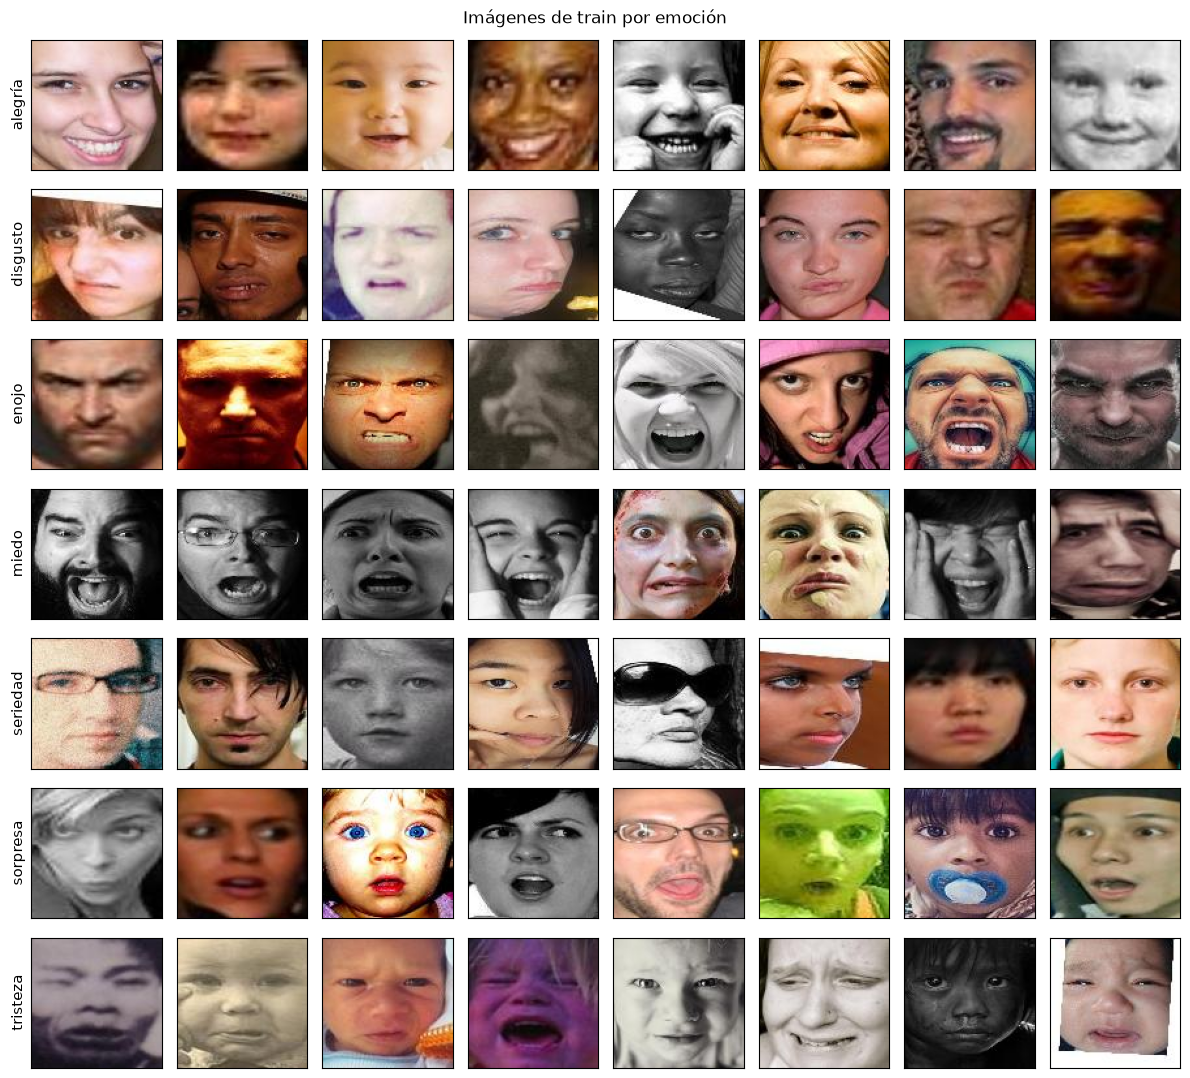

In [5]:
# ----------------------------------------------------------------------
# 8 EJEMPLOS DE CADA EMOCIÓN
# ----------------------------------------------------------------------
rng = np.random.default_rng(SEMILLA)
etiquetas = np.array(train_ds.targets)
fig, axes = plt.subplots(len(CLASES), 8, figsize=(12, 11))
for fila, clase in enumerate(CLASES):
    for ax, i in zip(axes[fila], rng.choice(np.flatnonzero(etiquetas == fila), 8, replace=False)):
        ax.imshow(Image.open(train_ds.samples[i][0]))
        ax.set_xticks([]); ax.set_yticks([])
    axes[fila, 0].set_ylabel(clase, fontsize=11)
fig.suptitle("Imágenes de train por emoción"); fig.tight_layout(); plt.show()

##### Tamaño, color y cómo son las fotos

Todas miden 100x100 y vienen en RGB, pero el 14.7% de las de train y el 14.3% de las de validación son en realidad fotos en blanco y negro: sus tres canales son casi iguales. En la grilla se ve que las caras ya vienen recortadas y alineadas, con los ojos más o menos a la misma altura, y que son fotos reales y muy variadas: bebés y personas mayores, anteojos, manos tapando parte de la cara, maquillaje y luces de colores. Algunas tienen esquinas blancas, que quedaron de rotarlas para alinear la cara. También hay expresiones que se parecen entre clases: varias caras de miedo tienen la boca abierta como las de sorpresa, y algunas de enojo están gritando.

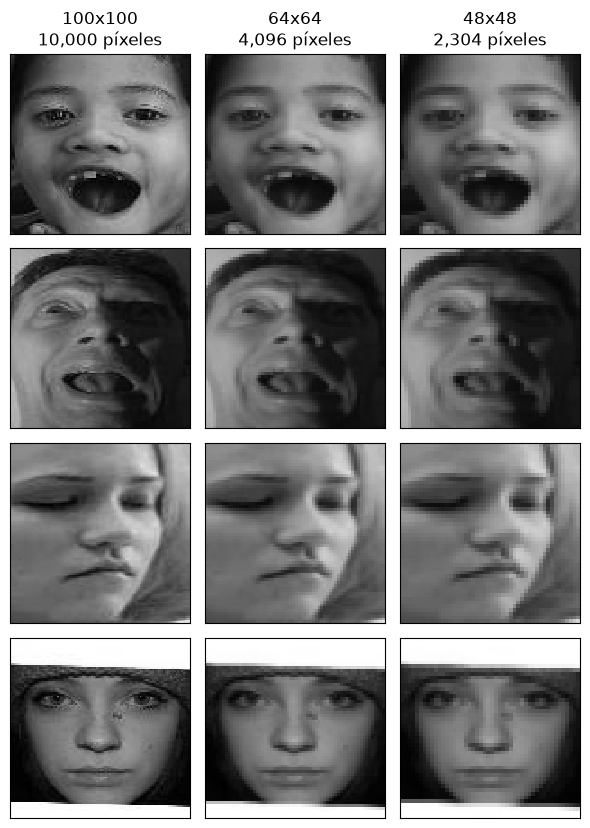

In [6]:
# ----------------------------------------------------------------------
# ¿A QUÉ TAMAÑO LAS PASO? 100x100 ORIGINAL CONTRA 64x64 Y 48x48
# ----------------------------------------------------------------------
LADOS = [100, 64, 48]
rng = np.random.default_rng(SEMILLA)
fig, axes = plt.subplots(4, len(LADOS), figsize=(6, 8.4))
for fila, i in enumerate(rng.choice(len(train_ds), 4, replace=False)):
    gris = Image.open(train_ds.samples[i][0]).convert("L")
    for ax, lado in zip(axes[fila], LADOS):
        ax.imshow(gris.resize((lado, lado), Image.BILINEAR), cmap="gray", vmin=0, vmax=255,
                  interpolation="nearest")          # sin suavizar al dibujar: se ven los píxeles reales de cada tamaño
        ax.set_xticks([]); ax.set_yticks([])
        if fila == 0:
            ax.set_title(f"{lado}x{lado}\n{lado * lado:,} píxeles")
fig.tight_layout(); plt.show()

##### A qué tamaño

Comparo cuatro caras a su tamaño original (100x100), a 64x64 y a 48x48, dibujadas con sus píxeles reales, sin suavizar. Las tres conservan la expresión, pero cuanto más chica es la imagen, menos píxeles quedan para los dientes, el borde de los ojos y las arrugas alrededor de la boca, que es lo que cambia entre emociones. Uso 64x64 como punto medio: tiene 2.4 veces menos píxeles que el original (4.096 contra 10.000), así que la red hace muchas menos cuentas por imagen, y no bajo a 48x48 para no perder más detalle del necesario.

píxeles de train: media 0.4816, desvío 0.2389


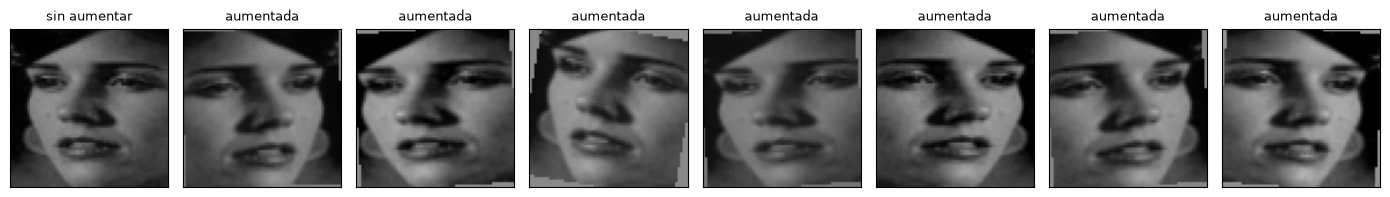

In [7]:
# ----------------------------------------------------------------------
# TRANSFORMACIONES DE VALIDACIÓN Y DE TRAIN
# ----------------------------------------------------------------------
TAM = 64

base = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize(TAM),                    # el lado más corto pasa a 64, sin deformar
    transforms.CenterCrop(TAM),                # recorte central cuadrado de 64x64
    transforms.ToTensor(),                     # tensor (1, 64, 64) con valores entre 0 y 1
])

# media y desvío de los píxeles de train ya pasados por base (gris, 64x64, escala 0-1)
X_base = torch.stack([base(Image.open(ruta)) for ruta, _ in train_ds.samples])
MEDIA, DESVIO = X_base.mean().item(), X_base.std().item()
print(f"píxeles de train: media {MEDIA:.4f}, desvío {DESVIO:.4f}")

normalizar = transforms.Normalize([MEDIA], [DESVIO])
tf_val = transforms.Compose([base, normalizar])
tf_train = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomResizedCrop(TAM, scale=(0.85, 1.0), ratio=(0.9, 1.1)),     # zoom, desplazamiento y un estiramiento leve
    transforms.RandomHorizontalFlip(),                                           # espejo, con probabilidad 0.5
    transforms.RandomRotation(10, interpolation=transforms.InterpolationMode.BILINEAR,
                              fill=round(MEDIA * 255)),                          # ±10°, las esquinas en gris medio
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    normalizar,
])

# la misma transformación de validación sirve para una imagen del dataset y para una foto rectangular a color
assert tf_val(Image.open(train_ds.samples[0][0])).shape == (1, TAM, TAM)
assert tf_val(Image.new("RGB", (800, 1200))).shape == (1, TAM, TAM)


def mostrar(ax, x, titulo=""):
    """Muestra un tensor normalizado (1, H, W) en su escala de grises original: 0 es negro y 1 es blanco."""
    ax.imshow(x[0] * DESVIO + MEDIA, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titulo, fontsize=9); ax.set_xticks([]); ax.set_yticks([])


# una imagen de train tal como la ve la red en validación y 7 versiones aumentadas
rng = np.random.default_rng(SEMILLA)
torch.manual_seed(SEMILLA)                     # las transformaciones al azar usan el generador de torch
img = Image.open(train_ds.samples[rng.integers(len(train_ds))][0])
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
mostrar(axes[0], tf_val(img), "sin aumentar")
for ax in axes[1:]:
    mostrar(ax, tf_train(img), "aumentada")
plt.tight_layout(); plt.show()

##### Decisión final del preprocesamiento

En la figura de arriba se ve una imagen de train sin aumentar y siete versiones aumentadas.

| aspecto | qué hago | por qué |
|---|---|---|
| Color | paso todo a escala de grises (1 canal) | La emoción está en la forma de la boca, los ojos y las cejas, no en el color, y el 14.7% de las fotos de train ni siquiera tiene color. En gris, una foto a color y una en blanco y negro le llegan a la red de la misma forma. |
| Tamaño | 64x64 | Conserva los rasgos de la expresión con 2.4 veces menos píxeles que el original. |
| Relación de aspecto | `Resize(64)` y `CenterCrop(64)` | Las imágenes del dataset son cuadradas, pero una foto cualquiera puede tener otra proporción. `Resize(64)` lleva el lado corto a 64 sin deformar y `CenterCrop(64)` recorta el centro. Si estirara una foto rectangular a 64x64, la cara quedaría más ancha o más angosta, y una boca estirada puede parecer una sonrisa. Con las imágenes del dataset estos dos pasos solo achican de 100 a 64. |
| Cambio de dimensionalidad | tensor de (1, 64, 64), sin aplanar | En el TP2 cada ejemplo era un vector. La CNN recibe la imagen como una grilla de canales, alto y ancho, y así sabe qué píxel está al lado de cuál. El aplanado lo hace la red recién al final. |
| Normalización | `ToTensor` y `Normalize` con la media (0.4816) y el desvío (0.2389) de train | `ToTensor` pasa los píxeles de 0-255 a 0-1 y `Normalize` los centra en 0 con desvío 1, como el StandardScaler del TP2, para que la red entrene más estable. La media y el desvío salen solo de train. |
| Balanceo | no cambio la cantidad de imágenes de cada clase; sigo el desbalance con el F1 macro y calculo pesos por clase para la función de costo | Submuestrear tiraría fotos de las clases grandes, y sobremuestrear repetiría muchas veces las mismas 281 fotos de miedo. Los pesos permiten compensar el desbalance sin tocar las imágenes, pero también pueden empeorar las clases grandes, así que hay que probarlos antes de usarlos. |
| Data augmentation, solo en train | recorte al azar del 85% al 100% del área (con un estiramiento leve, de hasta 10% entre ancho y alto), espejo, rotación de hasta ±10°, y brillo y contraste de ±20% | En cada época la red ve una versión distinta de cada foto y le cuesta más memorizarlas. Ninguno de estos cambios altera la emoción, y simulan lo que varía entre fotos reales: el encuadre, el lado, la inclinación de la cabeza y la luz. El estiramiento del recorte es chico: no se compara con estirar una foto rectangular entera a un cuadrado. No uso volteo vertical, porque no hay caras al revés, ni recortes grandes que puedan dejar afuera la boca o los ojos. En la rotación uso interpolación bilineal y relleno con el gris medio de train, que después de normalizar vale 0, lo mismo que el padding de las convoluciones, así que las esquinas quedan neutras. Con los valores por defecto (vecino más cercano y relleno negro) quedarían esquinas negras con bordes fuertes y serruchados. Validación no se aumenta: ahí quiero medir con las imágenes tal cual son. |

## 2. Construcción y entrenamiento del Modelo CNN (3.5 puntos)

- Construir una red neuronal convolucional con PyTorch, **sin usar modelos pre-entrenados**.
- Analizar correctamente qué funciones de activación se deben usar en cada etapa de la red, el learning rate a utilizar, la función de costo y el optimizador.
- Cosas como el número de capas, neuronas, número y tamaño de los kernels, entre otros, queda a criterio de ustedes, pero deben estar justificadas.

#### Respuesta 2

Función de costo y capa de salida. Cada cara tiene una sola emoción, así que es un problema de 7 clases excluyentes. La red termina en 7 neuronas sin activación, una por emoción, que dan 7 números llamados logits, y la función de costo es la cross-entropy (`CrossEntropyLoss`). Esa función pasa los logits por un softmax, que los convierte en 7 probabilidades positivas que suman 1, y toma −log de la probabilidad que la red le dio a la emoción correcta. Vale casi 0 cuando la red acierta con seguridad y crece mucho cuando se equivoca estando segura. Es la versión para varias clases de la BCE del TP2, y por la misma razón conviene que el softmax se aplique adentro de la función de costo y no en la red: la cuenta es más estable numéricamente ([documentación de PyTorch](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)). Uso softmax y no una sigmoide por clase porque las emociones compiten entre sí: si una sube, las otras tienen que bajar. Cuando quiero ver el score de cada emoción, aplico el softmax a mano.

Activaciones. ReLU en todas las capas ocultas, las convolucionales y la densa. Para entradas positivas su derivada vale 1, así que no achica el gradiente cuando vuelve hacia atrás por las 8 capas convolucionales y las 2 densas. La sigmoide y la tanh lo achican en cada capa, y con tantas capas el gradiente que llega a las primeras sería muy chico. En la salida no va ninguna activación, porque el softmax ya está en la función de costo.

Optimizador. Adam, como en el TP2. Ajusta el tamaño del paso de cada peso según cómo vinieron sus gradientes, y suele andar bien sin mucho ajuste. El learning rate no lo dejo en el valor por defecto: lo elijo con un LR range test.

In [8]:
# ----------------------------------------------------------------------
# LA RED
# ----------------------------------------------------------------------
def bloque(c_entrada, c_salida):
    """Dos convoluciones 3x3 con BatchNorm y ReLU, y un max pooling 2x2 que reduce el tamaño a la mitad."""
    return nn.Sequential(
        nn.Conv2d(c_entrada, c_salida, kernel_size=3, padding=1), nn.BatchNorm2d(c_salida), nn.ReLU(),
        nn.Conv2d(c_salida, c_salida, kernel_size=3, padding=1), nn.BatchNorm2d(c_salida), nn.ReLU(),
        nn.MaxPool2d(2),
    )


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        # 64x64 -> 32x32 -> 16x16 -> 8x8 -> 4x4, y los canales de 1 a 256
        self.features = nn.Sequential(bloque(1, 32), bloque(32, 64), bloque(64, 128), bloque(128, 256))
        self.clasificador = nn.Sequential(
            nn.Flatten(),                                   # 256 canales x 4 x 4 = 4096 valores
            nn.Linear(256 * 4 * 4, 256), nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, len(CLASES)),                    # 7 logits: el softmax lo aplica la función de costo
        )

    def forward(self, x):
        return self.clasificador(self.features(x))


# salida, parámetros y campo receptivo de cada bloque
red = CNN()
x = torch.zeros(1, 1, TAM, TAM)
campo, salto, filas = 1, 1, []
for i, b in enumerate(red.features, 1):
    x = b(x)
    campo += 5 * salto      # cada convolución 3x3 suma 2 saltos y el pooling 2x2 suma 1
    salto *= 2              # después del pooling, un paso equivale al doble de píxeles de la imagen original
    filas.append([f"bloque {i}", tuple(x.shape[1:]), f"{sum(p.numel() for p in b.parameters()):,}", f"{campo}x{campo}"])
filas.append(["clasificador", (len(CLASES),), f"{sum(p.numel() for p in red.clasificador.parameters()):,}", "-"])
print(pd.DataFrame(filas, columns=["parte", "salida (canales, alto, ancho)", "parámetros", "campo receptivo"]).to_string(index=False))
print(f"\nparámetros totales: {sum(p.numel() for p in red.parameters()):,}")

       parte salida (canales, alto, ancho) parámetros campo receptivo
    bloque 1                  (32, 32, 32)      9,696             6x6
    bloque 2                  (64, 16, 16)     55,680           16x16
    bloque 3                   (128, 8, 8)    221,952           36x36
    bloque 4                   (256, 4, 4)    886,272           76x76
clasificador                          (7,)  1,050,631               -

parámetros totales: 2,224,231


##### Arquitectura

La red es una VGG chica: 4 bloques de dos convoluciones cada uno y una parte densa al final. Una convolución pasa filtros de 3x3 (9 pesos que la red aprende) por toda la imagen, y cada filtro da un valor alto donde encuentra su patrón, por ejemplo un borde o la comisura de la boca. Al apilar bloques, los patrones simples se combinan en otros más grandes y complejos.

| decisión | por qué |
|---|---|
| dos convoluciones 3x3 por bloque | 3x3 es el filtro más chico que mira a los vecinos de cada píxel. Dos seguidas cubren una zona de 5x5 con 18 pesos en vez de 25, y con una ReLU más en el medio. Es la idea de VGG ([Simonyan y Zisserman, 2015](https://arxiv.org/abs/1409.1556)). |
| padding 1 | La convolución no cambia el tamaño de la imagen, así que el tamaño solo lo reduce el pooling. |
| max pooling 2x2 al final de cada bloque | Se queda con el valor más alto de cada cuadrado de 2x2: achica a la mitad y hace que un rasgo corrido un píxel dé lo mismo. |
| 4 bloques, de 32 a 256 canales | Cada vez que la imagen se achica a la mitad duplico los canales, así el costo de cada bloque queda parecido y hay más filtros para los patrones más complejos. El campo receptivo es la zona de la imagen original de la que depende cada valor: después del tercer bloque es de 36x36 y después del cuarto de 76x76, más que la imagen entera. Así las últimas convoluciones pueden combinar ojos y boca, que es como se lee una emoción. |
| BatchNorm después de cada convolución | Normaliza la salida de cada capa con la media y el desvío del batch. La red entrena más rápido y más estable ([Ioffe y Szegedy, 2015](https://arxiv.org/abs/1502.03167)). |
| dropout 0.5 solo antes de la última capa | Las convoluciones ya están regularizadas por el data augmentation y BatchNorm. Además, un dropout antes de una BatchNorm hace que la varianza de las activaciones sea distinta al entrenar y al evaluar ([Li et al., 2019](https://arxiv.org/abs/1801.05134)), así que lo pongo después de la última BatchNorm. Uso 0.5, el valor que proponen para capas densas los autores de dropout ([Srivastava et al., 2014](http://jmlr.org/papers/v15/srivastava14a.html)). |
| aplanar y capa densa de 256 | A 4x4 todavía queda la ubicación aproximada de cada rasgo (arriba los ojos, abajo la boca), y la capa densa lo combina todo para decidir. Las 256 neuronas resumen los 4.096 valores del último bloque antes de la salida. Con más neuronas crecería todavía más la parte de la red con más parámetros, que ya tiene 1.050.631 de los 2.224.231. |

In [9]:
# ----------------------------------------------------------------------
# DATOS PARA MEDIR Y EL BUCLE DE ENTRENAMIENTO
# ----------------------------------------------------------------------
BATCH, LR, EPOCAS = 128, 3e-4, 30
COLUMNAS = ["loss_train", "acc_train", "f1_train", "loss_val", "acc_val", "f1_val"]

# Para medir, train y validación pasan una sola vez por la transformación de validación y quedan como tensores.
X_train = normalizar(X_base).to(device)                 # X_base ya había pasado por base
y_train = torch.tensor(train_ds.targets, device=device)
X_val = torch.stack([tf_val(Image.open(ruta)) for ruta, _ in val_ds.samples]).to(device)
y_val = torch.tensor(val_ds.targets, device=device)


def logits_de(modelo, X):
    modelo.eval()                                       # dropout apagado y BatchNorm con sus estadísticas fijas
    with torch.no_grad():
        return torch.cat([modelo(xb) for xb in X.split(512)])


def medir(modelo, X, y):
    logits = logits_de(modelo, X)
    pred, real = logits.argmax(1).cpu().numpy(), y.cpu().numpy()
    return [nn.functional.cross_entropy(logits, y).item(), accuracy_score(real, pred), f1_score(real, pred, average="macro")]


def entrenar(aumentar=True, pesos_desde=None):
    """Adam con learning rate coseno durante EPOCAS épocas. Si pesos_desde es un número, desde esa época la función
    de costo usa los PESOS por clase del punto 1. Devuelve el modelo de la última época y las métricas de cada época."""
    torch.manual_seed(SEMILLA)
    imagenes = datasets.ImageFolder(DATASET_ROOT_TRAIN, transform=tf_train if aumentar else tf_val)
    lotes = DataLoader(imagenes, batch_size=BATCH, shuffle=True, num_workers=2, persistent_workers=True,
                       generator=torch.Generator().manual_seed(SEMILLA))
    modelo = CNN().to(device)
    sin_pesos, con_pesos = nn.CrossEntropyLoss(), nn.CrossEntropyLoss(weight=PESOS.to(device))
    opt = torch.optim.Adam(modelo.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCAS)    # el lr baja de LR a 0 en forma de coseno
    historial, inicio = [], time.time()
    for epoca in range(1, EPOCAS + 1):
        criterio = con_pesos if pesos_desde is not None and epoca >= pesos_desde else sin_pesos
        modelo.train()
        for xb, yb in lotes:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            criterio(modelo(xb), yb).backward()
            opt.step()
        scheduler.step()
        fila = dict(zip(COLUMNAS, medir(modelo, X_train, y_train) + medir(modelo, X_val, y_val)))
        historial.append(fila)
        if epoca == 1 or epoca % 5 == 0:
            print(f"época {epoca:2d} | loss train {fila['loss_train']:.3f} val {fila['loss_val']:.3f} | "
                  f"F1 macro train {fila['f1_train']:.3f} val {fila['f1_val']:.3f} | {time.time() - inicio:4.0f} s")
    return modelo, pd.DataFrame(historial, index=range(1, EPOCAS + 1))


def mostrar_historial(hist):
    tabla = hist.assign(brecha_f1=hist["f1_train"] - hist["f1_val"])            # brecha de F1 entre train y validación
    print(tabla.loc[[1] + list(range(5, len(hist) + 1, 5))].round(4).to_string())
    print(f"\npérdida de validación mínima: {hist['loss_val'].min():.4f} en la época {hist['loss_val'].idxmin()}")
    print(f"mejor F1 macro de validación: {hist['f1_val'].max():.4f} en la época {hist['f1_val'].idxmax()}")

##### Cómo entreno y cómo mido

- Batches de 128 imágenes: son 96 pasos por época, la GPU procesa muchas imágenes a la vez, y BatchNorm calcula la media y el desvío sobre suficientes imágenes como para que sean estables. Un `DataLoader` lee las fotos de train y les aplica el augmentation en el momento, así cada época ve versiones distintas.
- 30 épocas con un scheduler coseno: el learning rate arranca en su valor inicial y baja hasta 0 siguiendo medio coseno ([Loshchilov y Hutter, 2017](https://arxiv.org/abs/1608.03983)). Al principio da pasos grandes y al final pasos chicos. La cantidad de épocas fija cuánto dura esa bajada: con 30, en las últimas épocas las métricas de validación ya casi no cambian y cada entrenamiento tarda unos 5 minutos. Como en la última época el lr ya es casi 0, la red termina estable, y reporto siempre la última época, sin elegir la mejor mirando validación.
- Las métricas de cada época (costo, accuracy y F1 macro) las mido con la red en modo evaluación y sobre las imágenes sin aumentar, tanto en train como en validación. Si midiera train durante el entrenamiento, con fotos deformadas y dropout activo, los números de train saldrían más bajos de lo que son y la comparación con validación engañaría. El costo que guardo es siempre la cross-entropy sin pesos, para poder comparar todas las épocas y todos los modelos.
- Semilla fija y cuDNN en modo determinístico, para que re-ejecutar en la misma máquina dé lo mismo. En otra máquina, por ejemplo en la GPU de Colab, el entrenamiento no sigue exactamente el mismo camino (el dropout, por ejemplo, usa otro generador de números al azar) y los resultados cambian un poco. Los números del texto son los de la ejecución que quedó guardada.

el barrido cortó en el paso 285, con lr 5.0e-01
loss suavizada mínima 1.344 con lr 2.2e-03 | diez veces menos: 2.2e-04


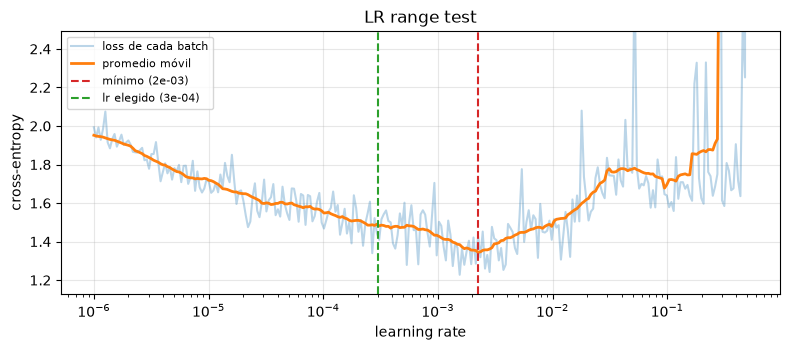

In [10]:
# ----------------------------------------------------------------------
# LR RANGE TEST: ¿QUÉ LEARNING RATE USO?
# ----------------------------------------------------------------------
def lr_range_test(pasos=300):
    """Entrena una red nueva subiendo el lr en cada batch, de 1e-6 a 1 en escala logarítmica, y guarda la loss
    de cada batch. Corta antes si la loss se dispara."""
    torch.manual_seed(SEMILLA)
    red = CNN().to(device)
    opt = torch.optim.Adam(red.parameters())
    lotes = DataLoader(datasets.ImageFolder(DATASET_ROOT_TRAIN, transform=tf_train), batch_size=BATCH, shuffle=True,
                       num_workers=2, generator=torch.Generator().manual_seed(SEMILLA))
    lrs, losses = np.geomspace(1e-6, 1.0, pasos), []
    red.train()
    while True:                                                # da más de una vuelta a train si hace falta
        for xb, yb in lotes:
            for grupo in opt.param_groups:
                grupo["lr"] = lrs[len(losses)]
            opt.zero_grad()
            loss = nn.functional.cross_entropy(red(xb.to(device)), yb.to(device))
            loss.backward()
            opt.step()
            losses.append(loss.item())
            if len(losses) == pasos or loss.item() > 4 * min(losses):    # fin del barrido, o la loss explotó
                return lrs[:len(losses)], np.array(losses)

lrs, losses = lr_range_test()
suave = pd.Series(losses).rolling(25, center=True, min_periods=1).mean().to_numpy()   # promedio de 25 batches centrado en cada paso
lr_minimo = lrs[suave.argmin()]
print(f"el barrido cortó en el paso {len(lrs)}, con lr {lrs[-1]:.1e}")
print(f"loss suavizada mínima {suave.min():.3f} con lr {lr_minimo:.1e} | diez veces menos: {lr_minimo / 10:.1e}")

plt.figure(figsize=(8, 3.6))
plt.plot(lrs, losses, alpha=.3, label="loss de cada batch")
plt.plot(lrs, suave, lw=2, label="promedio móvil")
plt.axvline(lr_minimo, color="tab:red", ls="--", label=f"mínimo ({lr_minimo:.0e})")
plt.axvline(LR, color="tab:green", ls="--", label=f"lr elegido ({LR:.0e})")
plt.xscale("log"); plt.ylim(min(losses) - 0.1, losses[0] + 0.5)
plt.xlabel("learning rate"); plt.ylabel("cross-entropy"); plt.title("LR range test")
plt.grid(alpha=.3); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

##### Learning rate

El LR range test entrena una red nueva subiendo el learning rate en cada batch, desde 1e-6 y en escala logarítmica, hasta llegar a 1 o hasta que la loss se dispara. La idea es de [Smith (2017)](https://arxiv.org/abs/1506.01186). Acá el barrido cortó en el paso 285, con un lr de 5.0e-01. En el gráfico la loss baja desde el principio, cada vez más despacio, llega a su mínimo con un lr de 2.2e-03 y después sube hasta dispararse. Para no depender del ruido de cada batch, busco el mínimo sobre un promedio de 25 batches centrado en cada paso. Una regla práctica es usar un lr unas 10 veces menor que el del mínimo, porque cerca del mínimo la red ya está por desestabilizarse ([Gugger, 2017](https://sgugger.github.io/how-do-you-find-a-good-learning-rate.html)). Eso da 2.2e-04, y uso 3e-4: está en ese orden de magnitud y en la zona en la que la loss todavía baja.

In [11]:
# ----------------------------------------------------------------------
# ENTRENAMIENTO DEL MODELO
# ----------------------------------------------------------------------
modelo, hist = entrenar()
print()
mostrar_historial(hist)

época  1 | loss train 1.329 val 1.307 | F1 macro train 0.207 val 0.208 |   12 s


época  5 | loss train 0.680 val 0.727 | F1 macro train 0.581 val 0.563 |   52 s


época 10 | loss train 0.549 val 0.642 | F1 macro train 0.653 val 0.631 |  101 s


época 15 | loss train 0.391 val 0.546 | F1 macro train 0.754 val 0.687 |  150 s


época 20 | loss train 0.282 val 0.513 | F1 macro train 0.847 val 0.740 |  199 s


época 25 | loss train 0.249 val 0.525 | F1 macro train 0.861 val 0.742 |  249 s


época 30 | loss train 0.221 val 0.501 | F1 macro train 0.877 val 0.748 |  298 s



    loss_train  acc_train  f1_train  loss_val  acc_val  f1_val  brecha_f1
1       1.3289     0.5018    0.2072    1.3065   0.5108  0.2077    -0.0005
5       0.6802     0.7636    0.5808    0.7273   0.7500  0.5626     0.0182
10      0.5491     0.8046    0.6526    0.6423   0.7735  0.6312     0.0213
15      0.3905     0.8630    0.7541    0.5462   0.8119  0.6869     0.0672
20      0.2818     0.9077    0.8470    0.5128   0.8276  0.7399     0.1071
25      0.2486     0.9174    0.8605    0.5246   0.8250  0.7419     0.1186
30      0.2210     0.9297    0.8767    0.5013   0.8321  0.7480     0.1287

pérdida de validación mínima: 0.5001 en la época 28
mejor F1 macro de validación: 0.7504 en la época 27


##### El entrenamiento

Este es el modelo final: sin pesos por clase, con data augmentation y lr inicial 3e-4. Las 30 épocas tardaron 298 segundos en mi computadora (GPU de una Mac, `mps`). Train y validación avanzan juntas hasta la época 10, con una brecha de F1 macro de 0.0213. Después train sigue subiendo y validación más despacio: la brecha llega a 0.1071 en la época 20 y termina en 0.1287. Aun así la loss de validación no empeora: tiene su mínimo, 0.5001, en la época 28, y termina en 0.5013. La red memoriza algo de train, pero en estas 30 épocas no pierde capacidad de generalizar. Al final, con el lr casi en 0, las métricas cambian poco, y la mejor F1 macro de validación (0.7504, en la época 27) es prácticamente la final (0.7480).

época  1 | loss train 1.903 val 1.904 | F1 macro train 0.203 val 0.195 |   13 s


época  5 | loss train 1.101 val 1.133 | F1 macro train 0.492 val 0.469 |   53 s


época 10 | loss train 0.876 val 0.910 | F1 macro train 0.651 val 0.626 |  102 s


época 15 | loss train 0.671 val 0.770 | F1 macro train 0.703 val 0.646 |  152 s


época 20 | loss train 0.500 val 0.651 | F1 macro train 0.788 val 0.693 |  201 s


...

época 15 | loss train 0.391 val 0.546 | F1 macro train 0.754 val 0.687 |  151 s


época 20 | loss train 0.282 val 0.513 | F1 macro train 0.847 val 0.740 |  201 s


época 25 | loss train 0.278 val 0.558 | F1 macro train 0.873 val 0.731 |  251 s


época 30 | loss train 0.267 val 0.552 | F1 macro train 0.874 val 0.727 |  301 s


                        sin pesos (modelo final)  pesos desde la época 1  pesos desde la época 21
accuracy val                               0.832                   0.778                    0.809
F1 macro val                               0.748                   0.701                    0.727
recall macro val                           0.733                   0.738                    0.756
F1 macro val, época 10                     0.631                   0.626                    0.631
F1 macro val, época 20                     0.740                   0.693                    0.740
recall alegría                             0.928                   0.846                    0.888
recall disgusto                            0.438                   0.612                    0.575
recall enojo                               0.802                   0.796                    0.796
recall miedo                               0.500                   0.635                    0.676
recall seriedad     

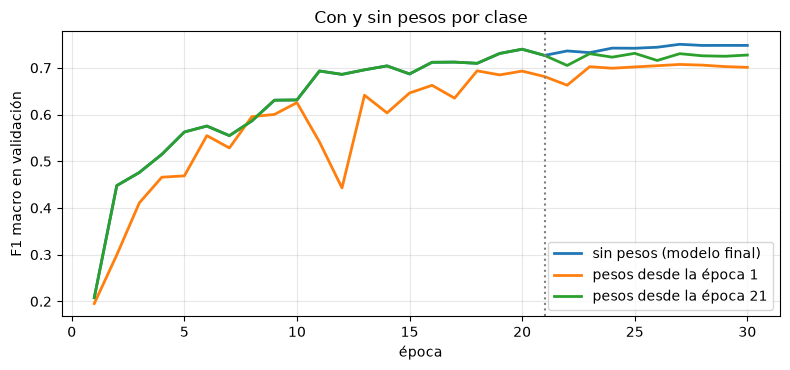

In [12]:
# ----------------------------------------------------------------------
# ¿CONVIENE USAR LOS PESOS POR CLASE? DESDE LA ÉPOCA 1 O SOLO EN LAS ÚLTIMAS 10
# ----------------------------------------------------------------------
PESOS_DESDE = 21
corridas = {"sin pesos (modelo final)": (modelo, hist),
            "pesos desde la época 1": entrenar(pesos_desde=1),
            f"pesos desde la época {PESOS_DESDE}": entrenar(pesos_desde=PESOS_DESDE)}

real_val = y_val.cpu().numpy()
filas = {}
for nombre, (m, h) in corridas.items():
    pred = logits_de(m, X_val).argmax(1).cpu().numpy()
    reporte = classification_report(real_val, pred, target_names=CLASES, output_dict=True, zero_division=0)
    fila = {"accuracy val": h["acc_val"].iloc[-1], "F1 macro val": h["f1_val"].iloc[-1],
            "recall macro val": reporte["macro avg"]["recall"],
            "F1 macro val, época 10": h["f1_val"].loc[10], "F1 macro val, época 20": h["f1_val"].loc[20]}
    fila.update({f"recall {c}": reporte[c]["recall"] for c in CLASES})
    fila.update({f"precisión {c}": reporte[c]["precision"] for c in ("disgusto", "enojo", "miedo")})
    filas[nombre] = fila
print(pd.DataFrame(filas).round(3).to_string())

plt.figure(figsize=(8, 3.8))
for nombre, (_, h) in corridas.items():
    plt.plot(h.index, h["f1_val"], lw=2, label=nombre)
plt.axvline(PESOS_DESDE, color="gray", ls=":")
plt.xlabel("época"); plt.ylabel("F1 macro en validación"); plt.title("Con y sin pesos por clase")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

##### ¿Uso los pesos por clase?

Entrené la misma red de tres formas: sin pesos, con los pesos del punto 1 desde la primera época, y con los pesos activados recién en la época 21, cuando el lr ya bajó. Esta última idea es de [Cao et al. (2019)](https://arxiv.org/abs/1906.07413): primero la red aprende a reconocer caras con todos los datos y recién al final se le pide que no ignore las clases chicas.

Los pesos suben el recall de las dos clases que peor salen sin ellos: miedo pasa de 0.500 sin pesos a 0.635 con pesos desde el principio y a 0.676 con pesos desde la época 21, y disgusto de 0.438 a 0.612 y 0.575. Enojo, en cambio, casi no cambia (de 0.802 a 0.796). Esa mejora se paga en precisión: con pesos desde el principio, la precisión de miedo cae de 0.860 a 0.470 y la de disgusto de 0.556 a 0.363, porque la red empieza a decir miedo y disgusto en fotos que no lo son. También bajan los recalls de las clases grandes, como seriedad (de 0.807 a 0.704) y alegría (de 0.928 a 0.846). En el balance el F1 macro baja: 0.748 sin pesos, 0.701 con pesos desde la época 1 y 0.727 con pesos desde la 21. El recall macro sí sube un poco con los pesos: 0.733, 0.738 y 0.756.

Con pesos desde el principio el entrenamiento además es más inestable: en el gráfico, el F1 macro de validación cae fuerte en la época 12 y queda por debajo de los otros dos casi todo el tiempo. Con pesos desde la época 21, las primeras 20 épocas son idénticas a las del modelo sin pesos (los dos tienen 0.740 de F1 en la época 20) y la diferencia aparece recién al final.

Me quedo con el modelo sin pesos: en esta corrida tiene el mejor F1 macro y el mejor accuracy, y es el más simple. La diferencia con los pesos desde la época 21 es chica para una sola corrida, así que no la tomo como prueba de que los pesos empeoran el modelo. Lo que sí muestra la tabla es el intercambio entre el recall de las clases chicas y la precisión: si importara más no perderse un caso de miedo que equivocarse diciendo miedo, convendría activar los pesos al final. Una aclaración: esta comparación la hago sobre validación, que es el mismo conjunto con el que evalúo el modelo elegido, así que sus números quedan un poco optimistas.

## 3. Evaluación del Modelo (2.5 puntos)

El modelo entrenado debe ser evaluado utilizando las siguientes métricas:

- **Accuracy**:
  - Reportar el valor final en el conjunto de validación.
  - Incluir una gráfica de evolución por época para entrenamiento y validación.

- **F1 Score Macro**:
  - Reportar el valor final en el conjunto de validación.
  - Incluir una gráfica de evolución por época para entrenamiento y validación.

- **Costo (Loss)**:
  - Mostrar una gráfica de evolución del costo por época para entrenamiento y validación.

- **Classification report**
  - Mostrar la precisión, recall y F1 score por cada clase usando `classification_report`

- **Matriz de confusión**:
  - Mostrar la matriz de confusión absoluta (valores enteros).
  - Mostrar la matriz de confusión normalizada (valores entre 0 y 1 por fila).

Se recomienda utilizar `scikit-learn` para calcular métricas como accuracy, F1 score, el Classification report y las matrices de confusión. Las visualizaciones pueden realizarse con `matplotlib` o `seaborn`.


#### Respuesta 3

Las curvas, el classification report y las matrices de confusión son del modelo final, sin pesos, sobre las 3.068 imágenes de validación. Al final lo comparo con la misma red entrenada sin data augmentation.

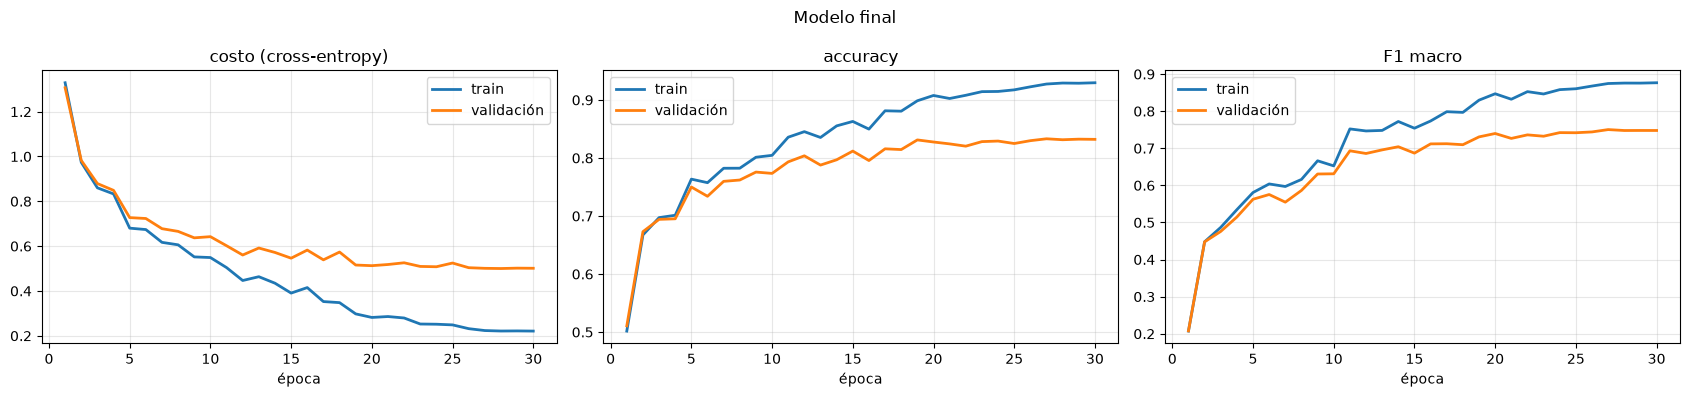

Validación, época 30: accuracy 0.8321 | F1 macro 0.7480


In [13]:
# ----------------------------------------------------------------------
# EVOLUCIÓN POR ÉPOCA
# ----------------------------------------------------------------------
def graficar_curvas(hist, titulo):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for ax, (clave, nombre) in zip(axes, [("loss", "costo (cross-entropy)"), ("acc", "accuracy"), ("f1", "F1 macro")]):
        ax.plot(hist.index, hist[f"{clave}_train"], lw=2, label="train")
        ax.plot(hist.index, hist[f"{clave}_val"], lw=2, label="validación")
        ax.set_title(nombre); ax.set_xlabel("época"); ax.grid(alpha=.3); ax.legend()
    fig.suptitle(titulo); fig.tight_layout(); plt.show()

graficar_curvas(hist, "Modelo final")
final = hist.iloc[-1]
print(f"Validación, época {hist.index[-1]}: accuracy {final['acc_val']:.4f} | F1 macro {final['f1_val']:.4f}")

##### Evolución por época y valores finales

Valores finales en validación, en la época 30: accuracy 0.8321 y F1 macro 0.7480. Para ubicarlos, un modelo que dijera siempre alegría tendría 38.6% de accuracy y un F1 macro muy bajo, porque las otras 6 clases tendrían F1 0.

En accuracy y en F1 macro, train y validación van juntas hasta la época 10 y después se separan de a poco; en el costo la separación empieza antes. El costo de validación baja hasta la época 20 y después queda casi quieto (0.5128 en la época 20 y 0.5013 en la 30), mientras el de train sigue bajando: la red sigue ajustándose a train sin mejorar en validación, aunque tampoco empeora. El F1 macro queda bastante por debajo del accuracy (0.7480 contra 0.8321) porque las clases chicas se clasifican peor, y el accuracy está dominado por alegría, que es el 38.6% de validación.

              precision    recall  f1-score   support

     alegría      0.931     0.928     0.929      1185
    disgusto      0.556     0.438     0.490       160
       enojo      0.714     0.802     0.756       162
       miedo      0.860     0.500     0.632        74
    seriedad      0.791     0.807     0.799       680
    sorpresa      0.844     0.839     0.841       329
    tristeza      0.761     0.818     0.788       478

    accuracy                          0.832      3068
   macro avg      0.780     0.733     0.748      3068
weighted avg      0.831     0.832     0.830      3068



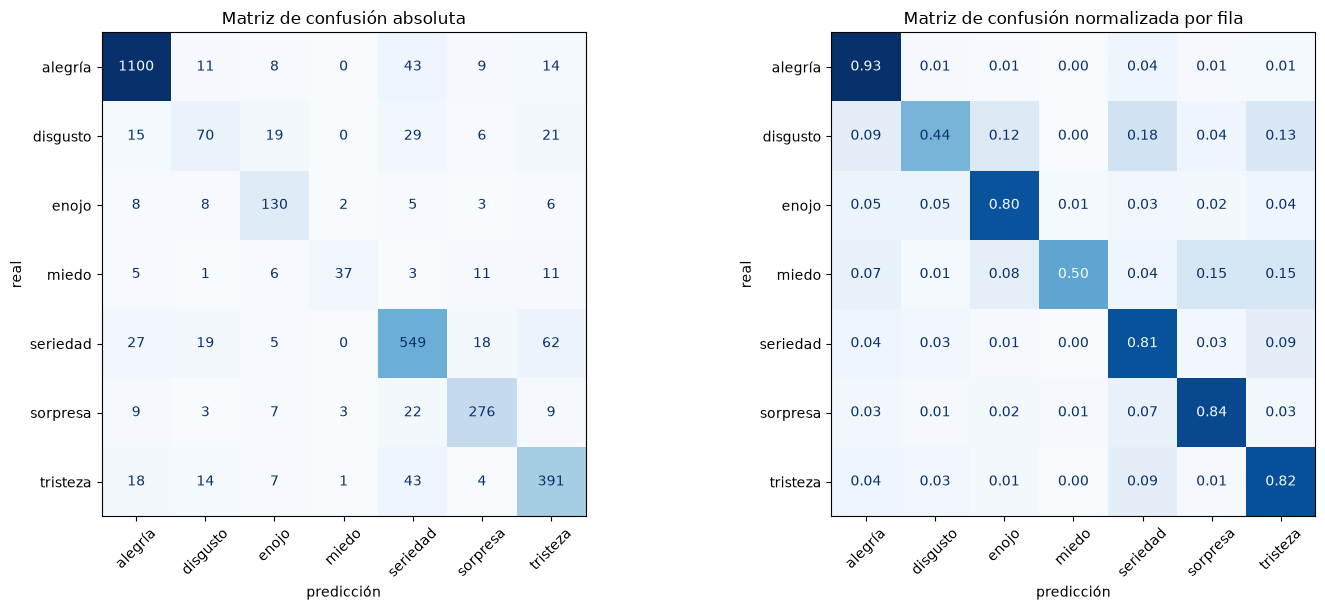

In [14]:
# ----------------------------------------------------------------------
# CLASSIFICATION REPORT Y MATRICES DE CONFUSIÓN EN VALIDACIÓN
# ----------------------------------------------------------------------
pred_val = logits_de(modelo, X_val).argmax(1).cpu().numpy()
real_val = y_val.cpu().numpy()
assert np.isclose(f1_score(real_val, pred_val, average="macro"), final["f1_val"])     # el mismo modelo de la tabla
print(classification_report(real_val, pred_val, target_names=CLASES, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, normalizar, formato, nombre in [(axes[0], None, "d", "absoluta"), (axes[1], "true", ".2f", "normalizada por fila")]:
    ConfusionMatrixDisplay.from_predictions(real_val, pred_val, display_labels=CLASES, normalize=normalizar,
                                            values_format=formato, cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Matriz de confusión {nombre}"); ax.set_xlabel("predicción"); ax.set_ylabel("real")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout(); plt.show()

##### Classification report y matrices de confusión

Por clase, la mejor es alegría (F1 0.929), seguida de sorpresa (0.841), seriedad (0.799), tristeza (0.788) y enojo (0.756). Las peores son miedo (0.632) y disgusto (0.490). Miedo tiene precisión alta (0.860) pero recall bajo (0.500): cuando la red dice miedo casi siempre acierta, pero se le escapa la mitad de los miedos. Miedo es la clase con menos fotos de train (281), pero la cantidad de datos no explica todo: disgusto tiene casi las mismas fotos que enojo (717 contra 705) y enojo llega a 0.756 de F1. También importa qué tan distinta es la expresión.

La matriz normalizada muestra adónde van los errores, y tienen sentido:

- Miedo se confunde con sorpresa (0.15) y con tristeza (0.15). Miedo y sorpresa comparten los ojos muy abiertos y las cejas levantadas, y muchas veces la boca abierta.
- Disgusto se confunde con seriedad (0.18), tristeza (0.13) y enojo (0.12). Es la expresión más sutil y la que más se mezcla: con el ceño fruncido se parece a enojo, y con la boca hacia abajo, a tristeza.
- Seriedad y tristeza se confunden entre sí (0.09 en las dos direcciones), porque una tristeza leve es casi una cara neutra.
- Alegría casi no se confunde (0.93 de recall), y sus pocos errores van sobre todo a seriedad (0.04).

época  1 | loss train 1.272 val 1.276 | F1 macro train 0.235 val 0.230 |   13 s


época  5 | loss train 0.419 val 0.707 | F1 macro train 0.715 val 0.628 |   52 s


época 10 | loss train 0.049 val 0.735 | F1 macro train 0.981 val 0.692 |  102 s


época 15 | loss train 0.003 val 0.972 | F1 macro train 1.000 val 0.690 |  151 s


época 20 | loss train 0.000 val 0.976 | F1 macro train 1.000 val 0.710 |  202 s


época 25 | loss train 0.000 val 1.059 | F1 macro train 1.000 val 0.711 |  252 s


época 30 | loss train 0.000 val 1.028 | F1 macro train 1.000 val 0.713 |  302 s


                        con augmentation (final) sin augmentation
accuracy val                              0.8321           0.8070
F1 macro val                              0.7480           0.7127
F1 macro train                            0.8767           1.0000
brecha F1 train - val                     0.1287           0.2873
loss val mínima (época)              0.5001 (28)       0.7072 (5)
loss val final                            0.5013           1.0277


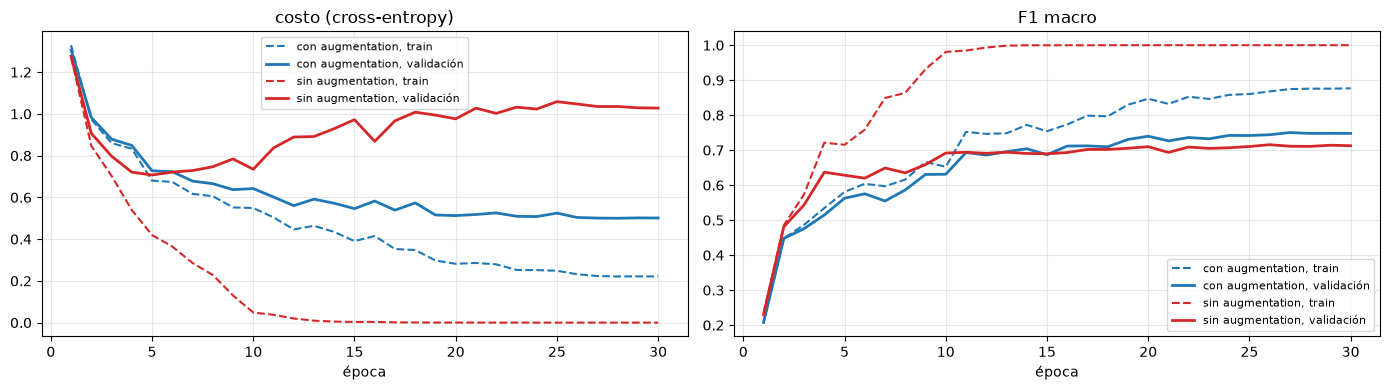

In [15]:
# ----------------------------------------------------------------------
# ¿QUÉ APORTA EL DATA AUGMENTATION? EL MISMO MODELO ENTRENADO SIN AUMENTAR
# ----------------------------------------------------------------------
modelo_sin_aug, hist_sin_aug = entrenar(aumentar=False)

def resumen_aug(h):
    u = h.iloc[-1]
    return {"accuracy val": f"{u['acc_val']:.4f}", "F1 macro val": f"{u['f1_val']:.4f}", "F1 macro train": f"{u['f1_train']:.4f}",
            "brecha F1 train - val": f"{u['f1_train'] - u['f1_val']:.4f}",
            "loss val mínima (época)": f"{h['loss_val'].min():.4f} ({h['loss_val'].idxmin()})",
            "loss val final": f"{u['loss_val']:.4f}"}

print(pd.DataFrame({"con augmentation (final)": resumen_aug(hist), "sin augmentation": resumen_aug(hist_sin_aug)}).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for nombre, h, color in [("con augmentation", hist, "tab:blue"), ("sin augmentation", hist_sin_aug, "tab:red")]:
    for ax, clave in zip(axes, ["loss", "f1"]):
        ax.plot(h.index, h[f"{clave}_train"], color=color, ls="--", label=f"{nombre}, train")
        ax.plot(h.index, h[f"{clave}_val"], color=color, lw=2, label=f"{nombre}, validación")
axes[0].set_title("costo (cross-entropy)"); axes[1].set_title("F1 macro")
for ax in axes:
    ax.set_xlabel("época"); ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

##### ¿Sirvió el data augmentation?

Entrené la misma red sin augmentation. Sin aumentar, la red memoriza train: el F1 macro de train llega a 1.000 en la época 15 y la loss de train a 0.000 en la 20. La loss de validación, en cambio, tiene su mínimo en la época 5 (0.7072) y después sube: llega a 1.059 en la época 25 y termina en 1.0277. Es el sobreajuste típico: la red se vuelve cada vez más segura de sus respuestas, también de las equivocadas. Con augmentation la brecha de F1 macro entre train y validación baja a menos de la mitad (0.1287 contra 0.2873) y el modelo termina mejor en validación: F1 macro 0.7480 contra 0.7127 y accuracy 0.8321 contra 0.8070.

 ## 4. Prueba de Imágenes Nuevas (1 punto)
Subir al menos 12 imágenes personales de cualquier ratio o relación de aspecto (pueden usar fotos del rostro de ustedes, rostros de personas generadas por IA o imágenes stock de internet), que no formen parte del dataset de entrenamiento ni de validación. Tampoco vale usar imágenes de otro dataset, deben ser imágenes sueltas.

- Debe haber al menos una imagen para cada emoción.

- Aplicar el mismo pre-procesamiento que se usó para el dataset de validation durante el entrenamiento del modelo.

- Pasar las imágenes por el modelo entrenado y mostrar:

  - La imagen original
  - La imagen pre-procesada (mismas transformaciones que durante el entrenamiento)
  - El score asignado a cada clase (normalizado de 0 a 1 o de 0% a 100%)
  - La clase ganadora inferida por el modelo

- Redactar conclusiones preliminares

#### Respuesta 4

Elegí 14 fotos de [Pexels](https://www.pexels.com), que se pueden usar libremente ([licencia](https://www.pexels.com/license/)), 2 por emoción. Busqué expresiones claras pero también variedad: fotos verticales, horizontales y casi cuadradas, primeros planos y planos más abiertos en los que la cara ocupa una parte chica, gente de distintas edades y una foto en blanco y negro. El notebook las baja de Pexels y abajo queda impreso el link de cada una. El nombre de cada archivo dice la emoción que yo esperaba ver.

A cada foto le aplico exactamente la transformación de validación (`tf_val`): gris, lado corto a 64, recorte central de 64x64 y normalización. Para cada una muestro la original, la imagen pre-procesada que entra a la red y el score de cada emoción, que es el softmax de los 7 logits (los 7 suman 100%).

In [16]:
# ----------------------------------------------------------------------
# DESCARGA DE LAS 14 FOTOS (PEXELS, LICENCIA LIBRE: https://www.pexels.com/license/)
# ----------------------------------------------------------------------
# nombre del archivo (emoción esperada _ número) -> id de la foto en https://www.pexels.com/photo/<id>/
FOTOS = {"alegria_1": 30518441, "alegria_2": 7047890, "tristeza_1": 7273344, "tristeza_2": 8173242,
         "enojo_1": 8727450, "enojo_2": 3769703, "miedo_1": 4584046, "miedo_2": 6471727,
         "sorpresa_1": 12644729, "sorpresa_2": 3777931, "disgusto_1": 4316720, "disgusto_2": 33715997,
         "seriedad_1": 8384894, "seriedad_2": 35466969}
ESPERADA = {nombre: NOMBRE[nombre.split("_")[0]] for nombre in FOTOS}
os.makedirs("data/nuevas", exist_ok=True)
for nombre, id_foto in FOTOS.items():
    ruta = f"data/nuevas/{nombre}.jpg"
    if not os.path.exists(ruta):
        url = f"https://images.pexels.com/photos/{id_foto}/pexels-photo-{id_foto}.jpeg?auto=compress&cs=tinysrgb&w=800"
        pedido = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})   # sin este encabezado Pexels responde 403
        with urllib.request.urlopen(pedido, timeout=60) as respuesta:
            datos = respuesta.read()             # primero se baja entera y recién después se guarda
        with open(ruta, "wb") as f:
            f.write(datos)
    w, h = Image.open(ruta).size
    print(f"{nombre:11} {w}x{h} (relación {w / h:.2f})  https://www.pexels.com/photo/{id_foto}/")

alegria_1   800x1421 (relación 0.56)  https://www.pexels.com/photo/30518441/
alegria_2   800x1200 (relación 0.67)  https://www.pexels.com/photo/7047890/
tristeza_1  800x533 (relación 1.50)  https://www.pexels.com/photo/7273344/
tristeza_2  800x600 (relación 1.33)  https://www.pexels.com/photo/8173242/
enojo_1     800x1200 (relación 0.67)  https://www.pexels.com/photo/8727450/
enojo_2     800x720 (relación 1.11)  https://www.pexels.com/photo/3769703/
miedo_1     800x1186 (relación 0.67)  https://www.pexels.com/photo/4584046/
miedo_2     800x1236 (relación 0.65)  https://www.pexels.com/photo/6471727/
sorpresa_1  800x996 (relación 0.80)  https://www.pexels.com/photo/12644729/
sorpresa_2  800x533 (relación 1.50)  https://www.pexels.com/photo/3777931/
disgusto_1  800x1200 (relación 0.67)  https://www.pexels.com/photo/4316720/
disgusto_2  800x1200 (relación 0.67)  https://www.pexels.com/photo/33715997/
seriedad_1  800x1200 (relación 0.67)  https://www.pexels.com/photo/8384894/
seriedad_2  80

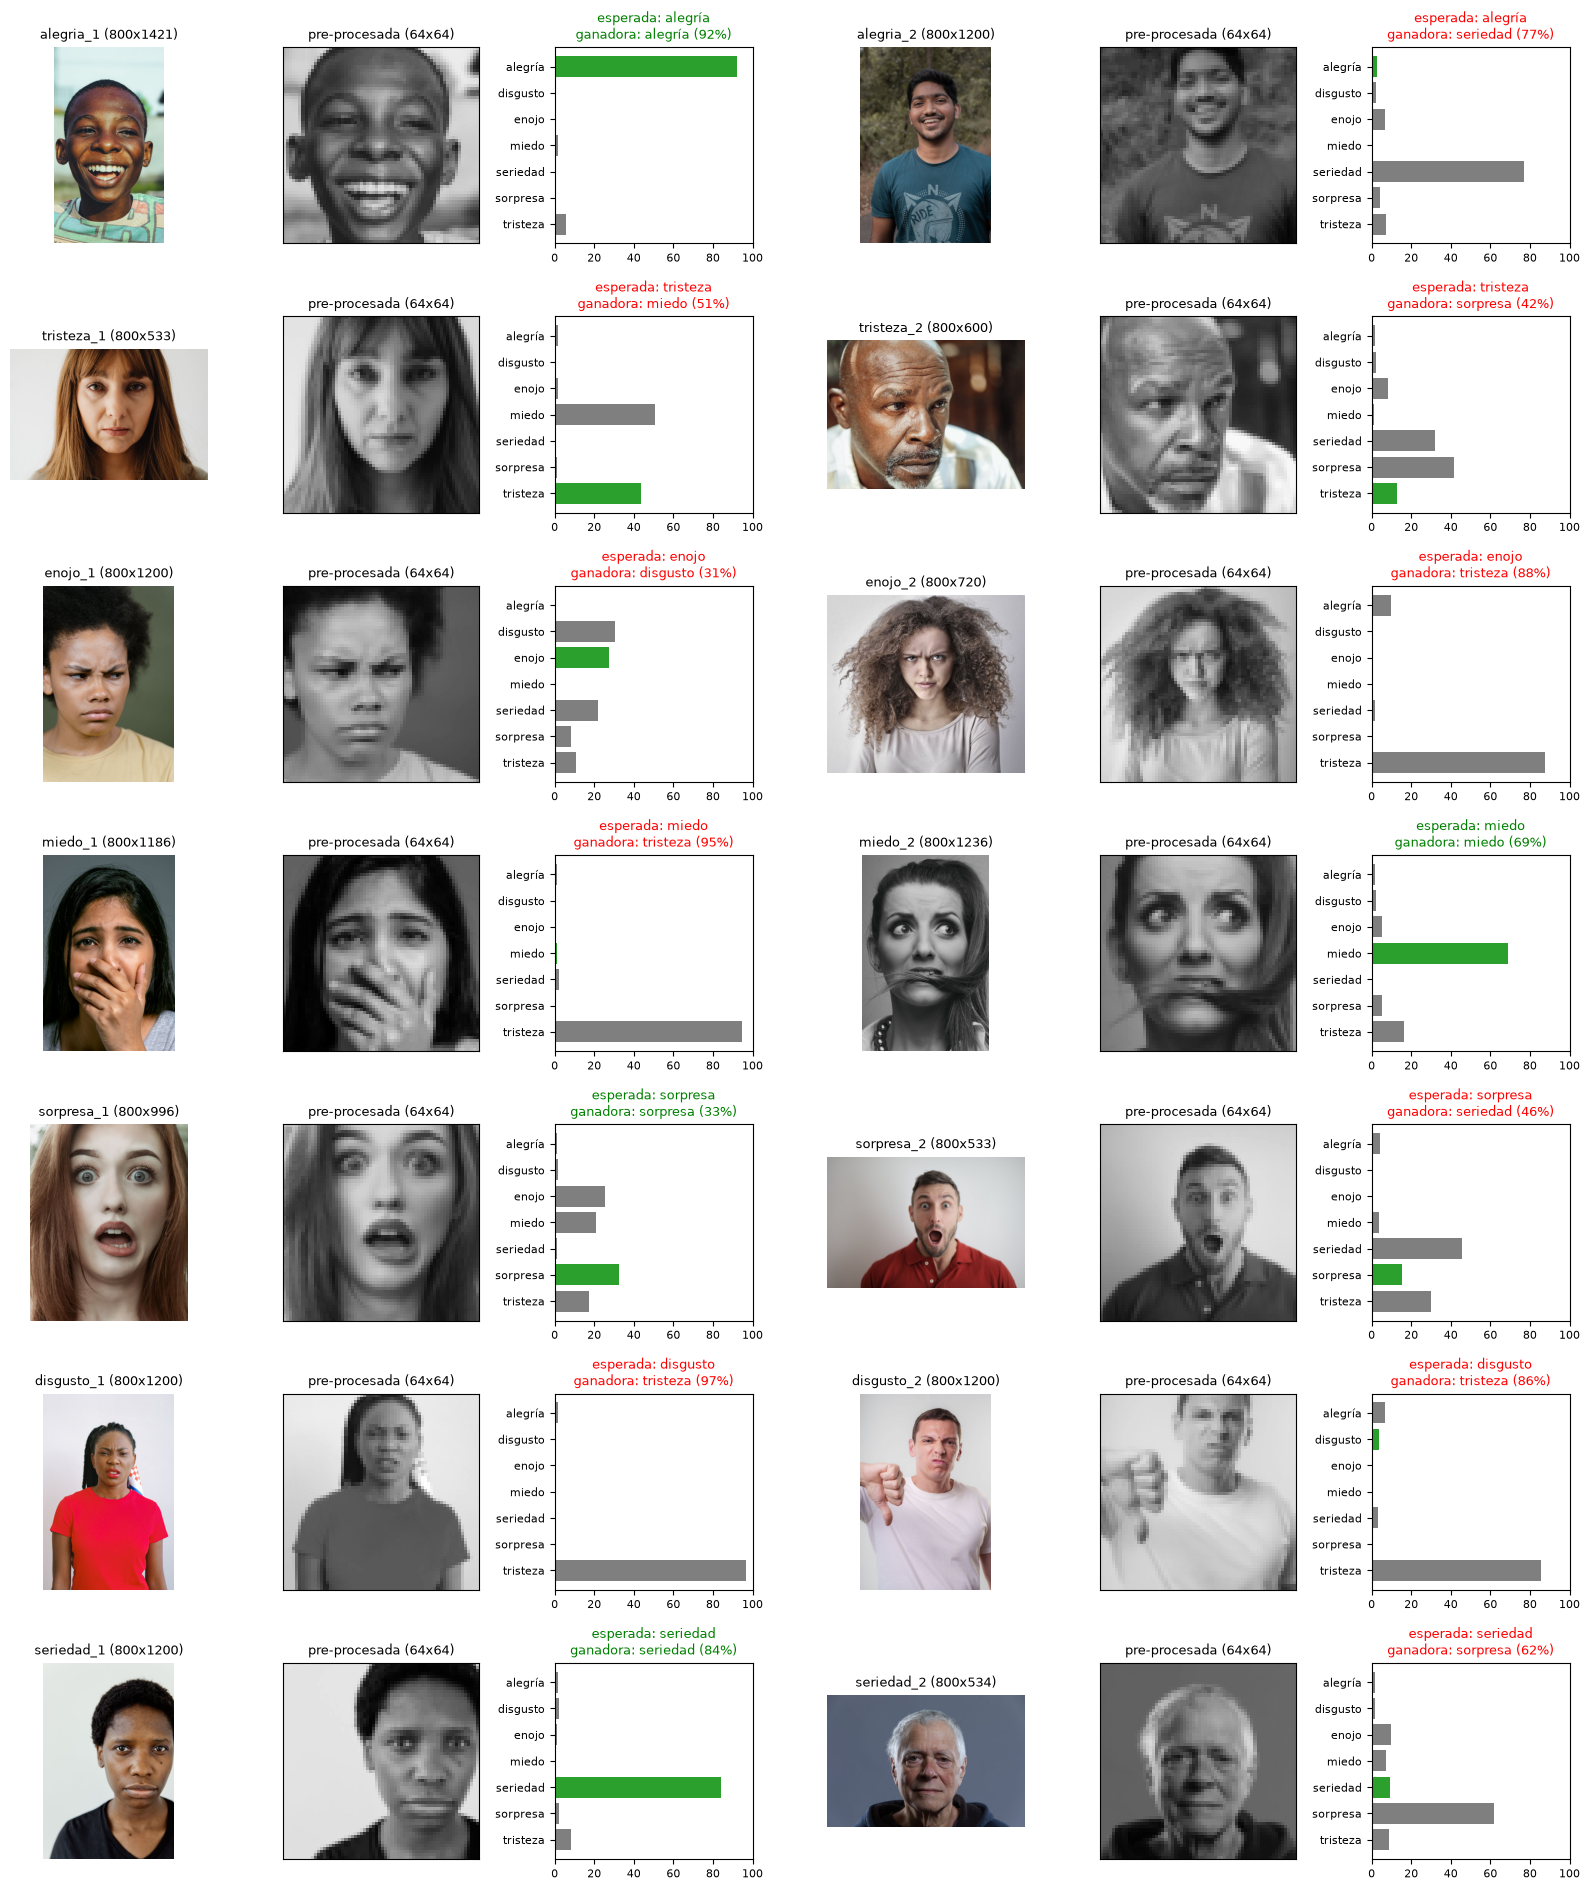

            esperada  ganadora  acierto  score ganadora  score esperada
foto                                                                   
alegria_1    alegría   alegría     True            0.92            0.92
alegria_2    alegría  seriedad    False            0.77            0.03
tristeza_1  tristeza     miedo    False            0.51            0.44
tristeza_2  tristeza  sorpresa    False            0.42            0.13
enojo_1        enojo  disgusto    False            0.31            0.28
enojo_2        enojo  tristeza    False            0.88            0.00
miedo_1        miedo  tristeza    False            0.95            0.01
miedo_2        miedo     miedo     True            0.69            0.69
sorpresa_1  sorpresa  sorpresa     True            0.33            0.33
sorpresa_2  sorpresa  seriedad    False            0.46            0.15
disgusto_1  disgusto  tristeza    False            0.97            0.00
disgusto_2  disgusto  tristeza    False            0.86         

In [17]:
# ----------------------------------------------------------------------
# PREDICCIÓN SOBRE LAS FOTOS ENTERAS
# ----------------------------------------------------------------------
def predecir(modelo, imagen):
    """La imagen con la transformación de validación y el score de cada emoción (softmax de los 7 logits)."""
    x = tf_val(imagen)
    prob = torch.softmax(logits_de(modelo, x.unsqueeze(0).to(device)), dim=1)[0].cpu().numpy()
    return x, prob


def barras(ax, prob, esperada):
    """Score de cada emoción en %. La barra de la emoción esperada va en verde."""
    ax.barh(CLASES, 100 * prob, color=["tab:green" if c == esperada else "tab:gray" for c in CLASES])
    ax.set_xlim(0, 100); ax.invert_yaxis(); ax.tick_params(labelsize=8)
    ganadora = CLASES[prob.argmax()]
    ax.set_title(f"esperada: {esperada}\nganadora: {ganadora} ({100 * prob.max():.0f}%)", fontsize=9,
                 color="green" if ganadora == esperada else "red")


def fila_resultado(nombre, prob):
    esperada, ganadora = ESPERADA[nombre], CLASES[prob.argmax()]
    return {"foto": nombre, "esperada": esperada, "ganadora": ganadora, "acierto": ganadora == esperada,
            "score ganadora": prob.max(), "score esperada": prob[CLASES.index(esperada)]}


resultados4, originales = [], {}
fig, axes = plt.subplots(7, 6, figsize=(16, 19))
for nombre, a in zip(FOTOS, axes.reshape(len(FOTOS), -1)):      # 3 paneles por foto, 2 fotos por fila
    original = originales[nombre] = Image.open(f"data/nuevas/{nombre}.jpg").convert("RGB")
    x, prob = predecir(modelo, original)
    a[0].imshow(original); a[0].set_title(f"{nombre} ({original.width}x{original.height})", fontsize=9); a[0].axis("off")
    mostrar(a[1], x, "pre-procesada (64x64)")
    barras(a[2], prob, ESPERADA[nombre])
    resultados4.append(fila_resultado(nombre, prob))
fig.tight_layout(); plt.show()

r4 = pd.DataFrame(resultados4).set_index("foto")
print(r4.round(2).to_string())
print(f"\naciertos: {r4['acierto'].sum()} de {len(r4)}")

##### Conclusiones preliminares

Con las fotos enteras la red acierta 4 de 14: alegria_1, miedo_2 y sorpresa_1, que son primeros planos, y seriedad_1, un retrato de frente sobre un fondo liso. Las 6 fotos en las que se ve más cuerpo, pelo o fondo que cara (alegria_2, enojo_2, sorpresa_2, disgusto_1, disgusto_2 y seriedad_2) fallan todas. En esas el recorte central de 64x64 incluye ropa y fondo, y la cara queda chica. La red nunca vio algo así y responde cualquier cosa, muchas veces con mucha seguridad: en disgusto_1 dice tristeza con 97%. La red aprendió con caras recortadas y alineadas, y para usarla con fotos comunes parece necesario darle lo mismo: primero encontrar la cara y recortarla.

Los primeros planos tampoco salen todos bien. En miedo_1 la mano tapa la boca y la red dice tristeza con 95%. En tristeza_1 y enojo_1 la emoción esperada queda segunda y cerca de la ganadora (44% contra 51%, y 28% contra 31%).

 ## 5. Prueba de Imágenes Nuevas con Pre-procesamiento Adicional (1 punto)
Las 12 imágenes del punto 4, ahora serán pasadas y recortadas por un algoritmo de detección de rostros. Usen el siguiente código para realizar un pre-procesamiento inicial de la imagen y ya luego aplican el pre-procesamiento que usaron al momento de entrenar el modelo.

- Pasar las imágenes por el modelo entrenado y mostrar:
  - La imagen original
  - La imagen recortada por el algoritmo
  - La imagen pre-procesada (mismas transformaciones del entrenamiento)
  - El score asignado a cada clase (normalizado de 0 a 1 o de 0% a 100%)
  - La clase esperada
  - La clase ganadora inferida por el modelo

- Analizar los casos en los que el modelo se equivoca e intentar identificar posibles causas, tales como:

  - Similitudes entre emociones.
  - Mezcla de 2 o más emociones en una misma expresión.

- Comparar los resultados con el punto 4 y redactar conclusiones finales.

**IMPORTANTE:** Ajusten los parámetros `scaleFactor`, `minNeighbors` y `minSize` según convenga para que la detección de rostros sea más efectiva y logre detectar rostros en sus 12 imágenes. No se queden necesariamente con los valores por defecto.

#### Respuesta 5

Uso el código de detección que viene con el TP, convertido en una función para aplicarlo a las 14 fotos. Le hice tres cambios. Si detecta más de una cara, me quedo con la más grande en lugar de `faces[0]`, que es simplemente la primera de la lista. Si no detecta ninguna, la foto sigue entera (queda anotado en el título) para que el notebook no se corte. Y dibujo el recuadro más grueso, para que se vea con la foto achicada.

Antes de llegar a estas 14 fotos descarté 2 de las que había elegido al principio, porque el detector no encontraba la cara con ninguna combinación de parámetros que probé: en una la cabeza estaba muy inclinada y en la otra la cara estaba tan cerca que no entraba entera. Así que detectar las 14 dice que estas fotos le resultan fáciles al detector, no que funcione con cualquier foto.

In [18]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def recortar_rostro(image_path, scaleFactor=1.1, minNeighbors=6, minSize=(30, 30)):
    """El código de detección del TP convertido en función, para aplicarlo a cada foto. Devuelve la imagen
    con los recuadros, el rostro recortado (o None) y la cantidad de detecciones. Si hay varias, uso la más grande."""
    image = cv2.imread(image_path)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(gray, scaleFactor=scaleFactor, minNeighbors=minNeighbors, minSize=minSize)

    image_with_box = image.copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(image_with_box, (x, y), (x + w, y + h), (0, 255, 0), 6)    # trazo más grueso para que se vea chico

    cropped_face_rgb = None
    if len(faces) > 0:
        (x, y, w, h) = max(faces, key=lambda f: f[2] * f[3])    # la detección más grande, en vez de faces[0]
        center_x, center_y = x + w // 2, y + h // 2
        side = max(w, h)
        half_side = side // 2

        x1 = max(center_x - half_side, 0)
        y1 = max(center_y - half_side, 0)
        x2 = min(center_x + half_side, image.shape[1])
        y2 = min(center_y + half_side, image.shape[0])

        cropped_face = image[y1:y2, x1:x2]
        cropped_face_rgb = cv2.cvtColor(cropped_face, cv2.COLOR_BGR2RGB)

    image_with_box_rgb = cv2.cvtColor(image_with_box, cv2.COLOR_BGR2RGB)
    return image_with_box_rgb, cropped_face_rgb, len(faces)

In [19]:
# ----------------------------------------------------------------------
# AJUSTE DE scaleFactor, minNeighbors Y minSize
# ----------------------------------------------------------------------
rutas = [f"data/nuevas/{nombre}.jpg" for nombre in FOTOS]
filas = []
for sf in (1.03, 1.05, 1.1):
    for mn in (3, 4, 5, 6):
        for ms in (30, 100):
            caras = [recortar_rostro(r, sf, mn, (ms, ms))[2] for r in rutas]
            filas.append([sf, mn, ms, sum(c >= 1 for c in caras), sum(c == 1 for c in caras), sum(c > 1 for c in caras)])
barrido = pd.DataFrame(filas, columns=["scaleFactor", "minNeighbors", "minSize", "fotos con alguna detección",
                                       "con una sola detección", "con varias"])
print(barrido.to_string(index=False))

PARAMETROS = dict(scaleFactor=1.03, minNeighbors=4, minSize=(100, 100))
print(f"\nelegidos: {PARAMETROS}. Fotos con más de una detección, en el orden en que las devuelve OpenCV:")
for ruta in rutas:
    caras = face_cascade.detectMultiScale(cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2GRAY), **PARAMETROS)
    if len(caras) > 1:
        print(f"  {os.path.basename(ruta)}: " + ", ".join(f"{w}x{h} en ({x}, {y})" for x, y, w, h in caras))

 scaleFactor  minNeighbors  minSize  fotos con alguna detección  con una sola detección  con varias
        1.03             3       30                          14                       7           7
        1.03             3      100                          14                      10           4
        1.03             4       30                          14                       9           5
        1.03             4      100                          14                      12           2
        1.03             5       30                          14                       9           5
        1.03             5      100                          14                      12           2
        1.03             6       30                          14                      11           3
        1.03             6      100                          13                      12           1
        1.05             3       30                          14                       7           7


  disgusto_2.jpg: 323x323 en (314, 168), 138x138 en (110, 475)


##### Ajuste del detector

El detector de Haar ([Viola y Jones, 2001](https://doi.org/10.1109/CVPR.2001.990517); [tutorial de OpenCV](https://docs.opencv.org/4.x/db/d28/tutorial_cascade_classifier.html)) recorre la imagen en varias escalas buscando contrastes de claro y oscuro típicos de una cara, por ejemplo que la zona de los ojos es más oscura que las mejillas. Tiene tres parámetros:

- `scaleFactor`: cuánto se achica la imagen entre una pasada y la siguiente. Cuanto más chico, más fina y más lenta es la búsqueda.
- `minNeighbors`: cuántas detecciones superpuestas hacen falta para aceptar una cara. Cuanto más alto, menos falsos positivos, pero puede perder caras.
- `minSize`: el tamaño mínimo de cara, en píxeles. Evita encontrar "caras" chiquitas en el fondo o en la ropa.

Probé 24 combinaciones. La tabla cuenta en cuántas fotos aparece alguna detección, no si esa detección es la cara: con valores permisivos aparecen recuadros en el fondo o en la ropa. Casi todas las combinaciones que detectan algo en las 14 fotos usan `scaleFactor` 1.03; con pasos más grandes entre una escala y la siguiente el detector se saltea alguna cara. La única excepción es 1.05 con `minNeighbors` 3 y `minSize` 30, que llena las fotos de recuadros: tiene varias detecciones en 7. Elegí `scaleFactor` 1.03, `minNeighbors` 4 y `minSize` 100: detecta algo en las 14 fotos y en 12 detecta una sola cosa, el máximo entre las combinaciones que encuentran algo en todas. Con `minNeighbors` 5 la tabla da lo mismo, pero con 6 una foto se queda sin detección, así que prefiero dejar un vecino de margen.

Las dos fotos con varias detecciones muestran por qué conviene quedarse con la más grande. En alegria_2, OpenCV devuelve primero un recuadro de 111x111 arriba a la izquierda, en las hojas del fondo: `faces[0]` le habría pasado ese pedazo de árbol a la red. La cara es el recuadro de 329x329, y el de 206x206 está en la remera. En disgusto_2 la cara (323x323) viene primero, y el otro recuadro, de 138x138, es el puño. En la figura de abajo se ve que en las 14 fotos la detección más grande es la cara.

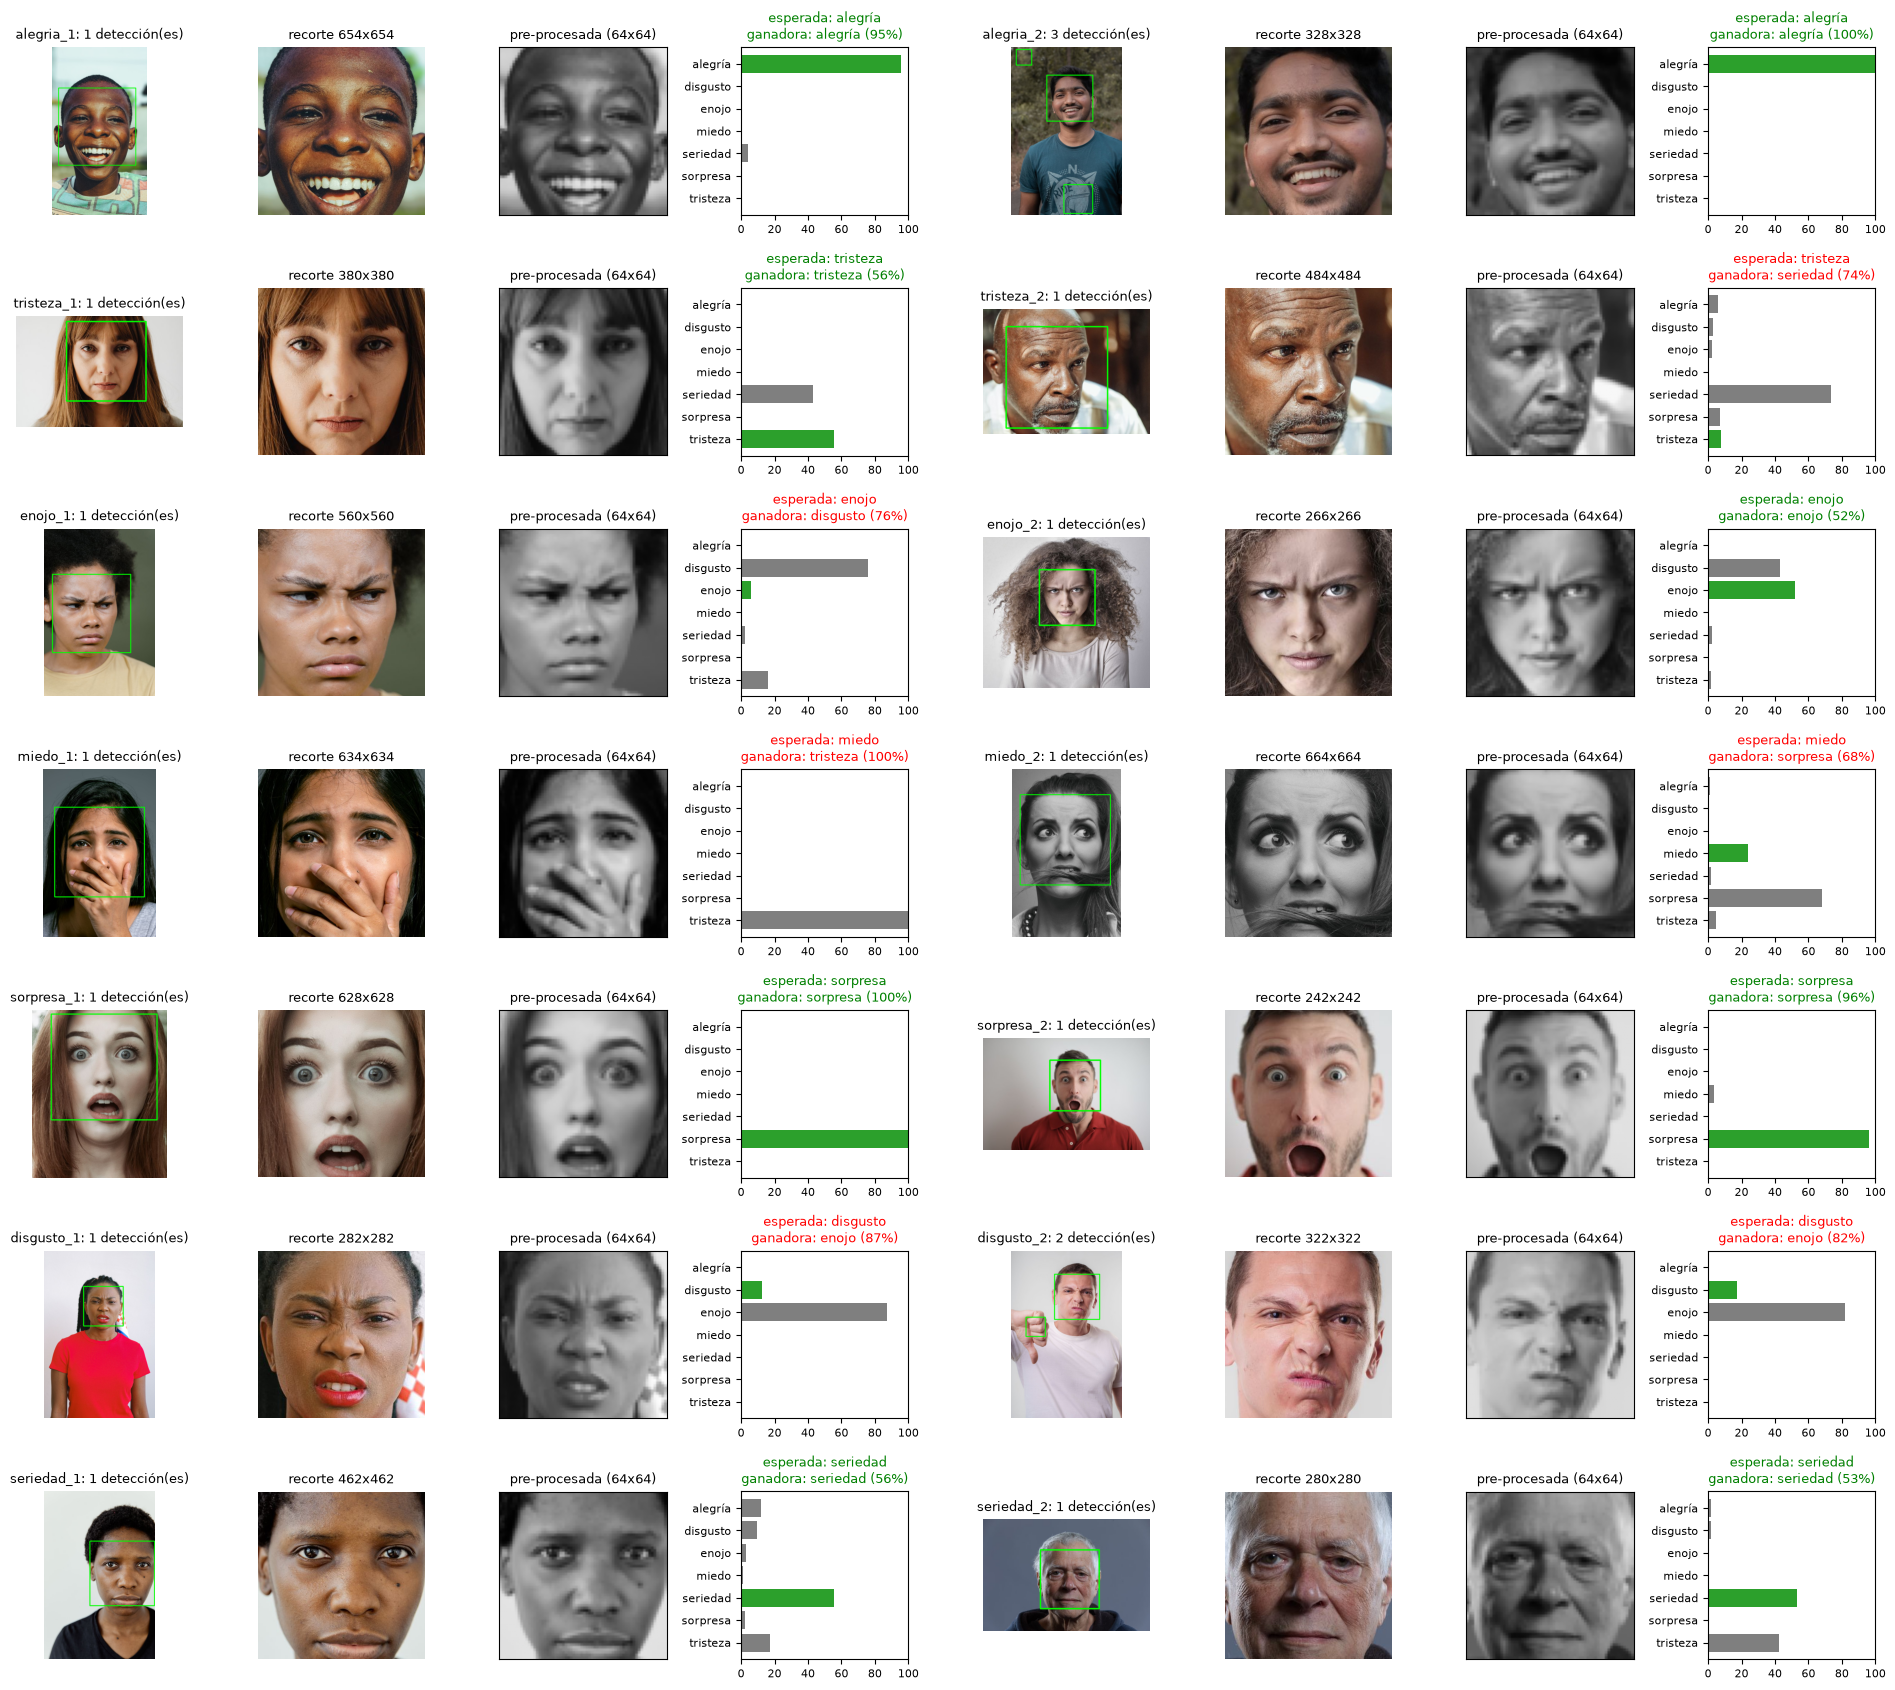

In [20]:
# ----------------------------------------------------------------------
# DETECCIÓN, RECORTE Y PREDICCIÓN
# ----------------------------------------------------------------------
resultados5, rostros = [], {}
fig, axes = plt.subplots(7, 8, figsize=(19, 17))
for nombre, a in zip(FOTOS, axes.reshape(len(FOTOS), -1)):      # 4 paneles por foto, 2 fotos por fila
    con_recuadros, rostro, n_caras = recortar_rostro(f"data/nuevas/{nombre}.jpg", **PARAMETROS)
    if rostro is None:                                           # sin detección: sigo con la foto entera y queda anotado
        rostro, titulo = con_recuadros, "sin detección: foto entera"
    else:
        titulo = f"recorte {rostro.shape[1]}x{rostro.shape[0]}"
    rostros[nombre] = Image.fromarray(rostro)
    x, prob = predecir(modelo, rostros[nombre])
    a[0].imshow(con_recuadros); a[0].set_title(f"{nombre}: {n_caras} detección(es)", fontsize=9); a[0].axis("off")
    a[1].imshow(rostro); a[1].set_title(titulo, fontsize=9); a[1].axis("off")
    mostrar(a[2], x, "pre-procesada (64x64)")
    barras(a[3], prob, ESPERADA[nombre])
    # lado del recorte dividido por el lado corto de la foto: cuánto de la foto ocupa la cara
    resultados5.append(fila_resultado(nombre, prob) | {"cara / lado corto": rostro.shape[0] / min(con_recuadros.shape[:2]) if n_caras else np.nan})
fig.tight_layout(); plt.show()

r5 = pd.DataFrame(resultados5).set_index("foto")

In [21]:
# ----------------------------------------------------------------------
# FOTO ENTERA CONTRA ROSTRO RECORTADO
# ----------------------------------------------------------------------
comparacion = pd.DataFrame({
    "esperada": r4["esperada"], "cara / lado corto": r5["cara / lado corto"],
    "ganadora foto entera": r4["ganadora"], "score esperada foto entera": r4["score esperada"],
    "ganadora recorte": r5["ganadora"], "score esperada recorte": r5["score esperada"],
})
print(comparacion.round(2).to_string())
print(f"\naciertos con la foto entera: {r4['acierto'].sum()} de {len(r4)} | con el rostro recortado: {r5['acierto'].sum()} de {len(r5)}")
print(f"score medio de la emoción esperada: {r4['score esperada'].mean():.2f} con la foto entera y "
      f"{r5['score esperada'].mean():.2f} con el recorte")

abiertas = r5["cara / lado corto"] < 0.6        # la cara ocupa menos del 60% del lado corto de la foto
for grupo, filtro in [("planos abiertos (cara < 60% del lado corto)", abiertas), ("primeros planos", ~abiertas)]:
    print(f"{grupo}: {filtro.sum()} fotos | aciertos con la foto entera {r4.loc[filtro, 'acierto'].sum()}, "
          f"con el recorte {r5.loc[filtro, 'acierto'].sum()}")

# Con 14 fotos un solo modelo puede acertar o fallar por poco. Repito la cuenta con los otros tres modelos entrenados.
def aciertos(m, imagenes):
    return sum(CLASES[predecir(m, imagenes[n])[1].argmax()] == ESPERADA[n] for n in FOTOS)

otros = {nombre: m for nombre, (m, _) in corridas.items()} | {"sin augmentation": modelo_sin_aug}
robustez = pd.DataFrame({nombre: {"aciertos foto entera": aciertos(m, originales), "aciertos recorte": aciertos(m, rostros)}
                         for nombre, m in otros.items()}).T
print("\n" + robustez.to_string())

            esperada  cara / lado corto ganadora foto entera  score esperada foto entera ganadora recorte  score esperada recorte
foto                                                                                                                             
alegria_1    alegría               0.82              alegría                        0.92          alegría                    0.95
alegria_2    alegría               0.41             seriedad                        0.03          alegría                    1.00
tristeza_1  tristeza               0.71                miedo                        0.44         tristeza                    0.56
tristeza_2  tristeza               0.81             sorpresa                        0.13         seriedad                    0.08
enojo_1        enojo               0.70             disgusto                        0.28         disgusto                    0.06
enojo_2        enojo               0.37             tristeza                        0.00  


                          aciertos foto entera  aciertos recorte
sin pesos (modelo final)                     4                 8
pesos desde la época 1                       5                 7
pesos desde la época 21                      3                 8
sin augmentation                             2                 3


##### Errores y conclusiones finales

Con el rostro recortado la red acierta 8 de 14, contra 4 con la foto entera, y el score medio de la emoción esperada sube de 0.28 a 0.48. La mejora está en los planos abiertos: en las 7 fotos en las que la cara ocupa menos del 60% del lado corto, los aciertos pasan de 1 a 5, y en los 7 primeros planos quedan en 3. Por ejemplo, alegria_2 pasa de seriedad a alegría con 100%, y sorpresa_2, de seriedad a sorpresa con 96%.

Con 14 fotos, que un modelo acierte una foto más o una menos puede depender de detalles del entrenamiento. Por eso repetí la cuenta con los otros tres modelos que entrené: los cuatro aciertan más con el recorte que con la foto entera (8 contra 4, 7 contra 5, 8 contra 3, y 3 contra 2 el modelo sin augmentation). Ese último es además el que peor anda con las fotos nuevas, igual que en validación.

Los 6 errores que quedan con el recorte coinciden con las confusiones de la matriz de validación:

- disgusto_1 y disgusto_2 salen enojo, con 87% y 82%. Las dos caras tienen el ceño fruncido y la nariz arrugada, que aparecen en las dos emociones. En validación el 12% de disgusto también se va a enojo, y disgusto es la clase que peor aprendió la red.
- enojo_1 sale disgusto, con 76%: el error inverso, por la misma razón.
- miedo_2 sale sorpresa con 68%, y miedo queda segundo con 24%. Los ojos muy abiertos aparecen en las dos emociones, y la boca, que ayudaría a distinguirlas, está tapada por el pelo. En validación el 15% de miedo se va a sorpresa. Con la foto entera esta salía bien, así que recortar no siempre ayuda.
- miedo_1 sale tristeza con 100%. La mano tapa toda la boca y solo quedan los ojos y las cejas, levantadas en el centro, un gesto que también aparece en la tristeza. En validación otro 15% de miedo se va a tristeza.
- tristeza_2 sale seriedad con 74%. La expresión es muy leve, la cara está un poco girada y lo más notorio son los ojos húmedos, que en gris y a 64x64 casi no se ven. Seriedad y tristeza son el par que más se confunde en validación.

Varios de estos casos son mezclas o expresiones ambiguas: el hombre de disgusto_2 hace a la vez un gesto de rechazo y de enojo, y la mujer de miedo_2 podría estar asustada o sorprendida. En casos así ni siquiera las personas se ponen de acuerdo.

Conclusiones finales:

- El modelo llega a 0.832 de accuracy y 0.748 de F1 macro en validación. Reconoce muy bien alegría y sorpresa, y le cuestan miedo y disgusto: sus expresiones se parecen a las de otras clases y, en el caso de miedo, hay muy pocas fotos.
- El data augmentation redujo mucho el sobreajuste: sin él la brecha de F1 macro entre train y validación es más del doble, y el modelo anda peor en validación y con las fotos nuevas. Los pesos por clase, en esta corrida, cambiaron qué clases se priorizan, pero no mejoraron el F1 macro.
- Con fotos nuevas el encuadre importa mucho: la red aprendió con caras recortadas, y recortar la cara antes mejora las predicciones en las fotos abiertas, con los cuatro modelos.
- Con 14 fotos estos números son orientativos: entrenando otra vez, algunas predicciones dudosas pueden cambiar. Lo que sí se repite es el tipo de errores, que son los mismos que en validación.